<a href="https://colab.research.google.com/github/cherniak1410-sketch/statistics_lab1/blob/main/lab1_final_ready_to_submit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab01 - sprint 1


## Общее описание данных
**Источник:** Wine Quality (белые вина), UCI Machine Learning Repository; Cortez P., Cerdeira A., Almeida F., Matos T., Reis J. Modeling wine preferences by data mining from physicochemical properties. Decision Support Systems, 2009.

**Что это за данные:** таблица из 4898 белых вин «Vinho Verde» (север Португалии), 12 столбцов. Одиннадцать столбцов — физико-химические показатели, измеренные в лаборатории: fixed acidity, volatile acidity, citric acid, residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide, density, pH, sulphates, alcohol. Двенадцатый столбец, quality, — оценка качества от 0 до 10, которую выставляют дегустаторы (это медиана нескольких экспертных оценок). Пропусков нет, все показатели числовые, одна строка — один образец вина. Значения получены измерением образцов в лаборатории, а не вычислены по формулам, поэтому для каждой бутылки они заранее неизвестны.

**Три выбранные величины:** pH, residual sugar (г/л), alcohol (% об.). Почему выбрала именно их: у них три разных «характера» распределения, и это интересно сравнивать. pH почти колоколообразный, с небольшим правым хвостом. Residual sugar сильно скошен вправо с длинным хвостом (асимметрия 1.08, эксцесс 3.47). Alcohol дискретизован (всего 103 значения) и имеет несколько пиков. Кроме того, у них разная связь друг с другом: pH и alcohol слабо коррелируют (r = 0.12), а alcohol и residual sugar связаны заметно (r = −0.45), и этому есть химическое объяснение (брожение превращает сахар в спирт). Это удобно для заданий про независимость и подбор распределений.

### Загрузка и первый взгляд

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Общие параметры для всей работы
SEED = 42          # один seed для всех разделов
N_SAMPLE = 500     # размер выборки для сравнений и гипотез
COLOR = "#6389B8"  # основной цвет графиков

# Единый стиль графиков
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=[COLOR, "#E4572E", "#76B391", "#F3A712"])
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["figure.dpi"] = 100

In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
df = pd.read_csv(url, sep=";")

print("Размер таблицы (строк, столбцов):", df.shape)
df.head()

Размер таблицы (строк, столбцов): (4898, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


### Пропуски и дубликаты

In [ ]:
print("Дубликатов:", df.duplicated().sum())

Дубликатов: 937


**Дубликаты.** В таблице 937 одинаковых строк (около 19%). Что я с ними делаю: оставляю. Почему: в таблице нет идентификатора вина, а значения округлены, поэтому две разные бутылки (например, из одной партии) могут дать одинаковые измерения всех 11 показателей и одну и ту же оценку качества. Доказать, что это ошибка записи, а не реальные вина, нельзя, а удаление 19% наблюдений изменило бы выборку.
Все дальнейшие расчёты сделаны с дубликатами (4898 строк).

### Три величины: общий EDA

In [ ]:
df[["pH", "residual sugar", "alcohol"]].describe()

,pH,residual sugar,alcohol
count,4898.000000,4898.000000,4898.000000
mean,3.188267,6.391415,10.514267
std,0.151001,5.072058,1.230621
min,2.720000,0.600000,8.000000
25%,3.090000,1.700000,9.500000
50%,3.180000,5.200000,10.400000
75%,3.280000,9.900000,11.400000
max,3.820000,65.800000,14.200000


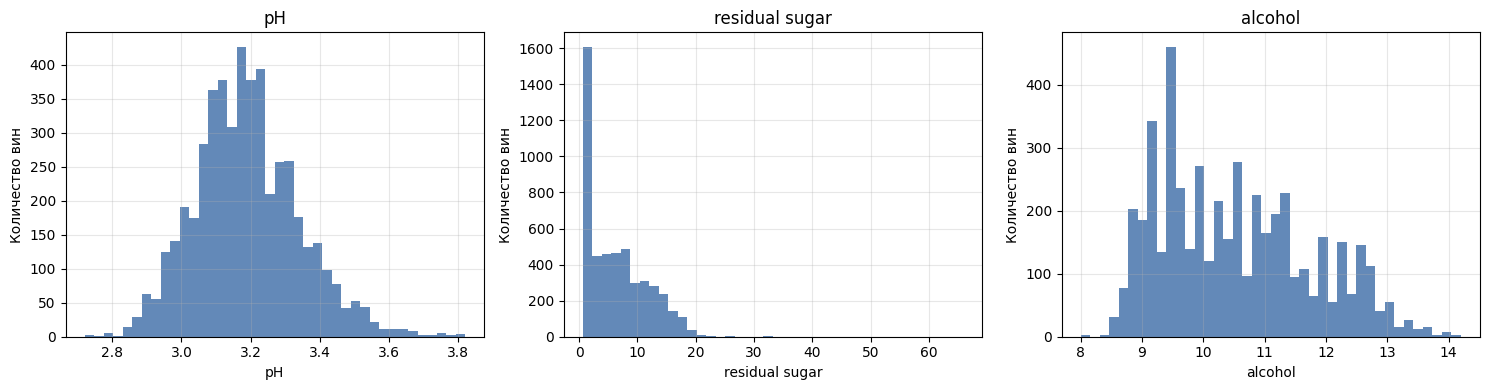

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["pH", "residual sugar", "alcohol"]):
    ax.hist(df[col], bins=40)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Количество вин")
plt.tight_layout()
plt.show()

**Что видно на гистограммах**

- **pH:** похож на колокол с пиком около 3.2, справа небольшой хвост.
- **residual sugar:** около 1600 вин имеют сахар меньше 2, дальше значения плавно спадают до 20, и есть редкие вина до 65. Длинный правый хвост.
- **alcohol:** график неровный, с зубцами и несколькими пиками (около 9.5, 10.5, 11, 12). Зубцы появились потому, что в данных всего 103 разных значения спирта на 4898 вин, и при 40 столбиках одни столбики захватывают лишнее «круглое» значение, а другие нет.

In [ ]:
print("Уникальных значений alcohol:", df["alcohol"].nunique())
print(df["alcohol"].value_counts().head(10))

Уникальных значений alcohol: 103
alcohol
9.4     229
9.5     228
9.2     199
9.0     185
10.0    162
10.5    160
11.0    158
10.4    153
9.1     144
9.8     136
Name: count, dtype: int64


In [ ]:
cols = ["pH", "residual sugar", "alcohol"]
print(df[cols].skew())
print(df[cols].kurt())

pH                0.457783
residual sugar    1.077094
alcohol           0.487342
dtype: float64
pH                0.530775
residual sugar    3.469820
alcohol          -0.698425
dtype: float64


## Random Variable 01 (pH)


### Description


**Величина:** pH белого вина (датасет Wine Quality, 4898 измерений).

| Параметр | Значение |
|---|---|
| Единицы измерения | безразмерная величина; $\mathrm{pH}=-\lg a(\mathrm{H}^+)$ |
| Тип | непрерывная |
| Диапазон в данных | от 2.72 до 3.82 |
| Среднее | 3.19 |

**Почему pH случайная величина**

1. **Значение зависит от многих факторов, которые заранее неизвестны:**
   сорт винограда, погода в год урожая, зрелость ягод, условия брожения.
2. **Без данных о составе и активностях ионов значение заранее неизвестно.**
   Определение pH через активность ионов водорода справедливо для любых водных растворов,
   в том числе сложных смесей. Однако состав конкретного вина и соответствующая
   активность ионов заранее неизвестны, поэтому pH определяют экспериментально.
3. **Измерение даёт шум.**
   Даже у бутылок из одной партии значения немного отличаются из-за
   погрешности pH-метра и температуры при замере.

**Вывод:** при случайном выборе образца его pH заранее неизвестен и может рассматриваться как случайная величина.


### EDA & Distribution


#### Описательные статистики

                   pH
n           4898.0000
среднее        3.1883
медиана        3.1800
мода           3.1400
std            0.1510
min            2.7200
max            3.8200
Q1             3.0900
Q3             3.2800
асимметрия     0.4578
эксцесс        0.5308


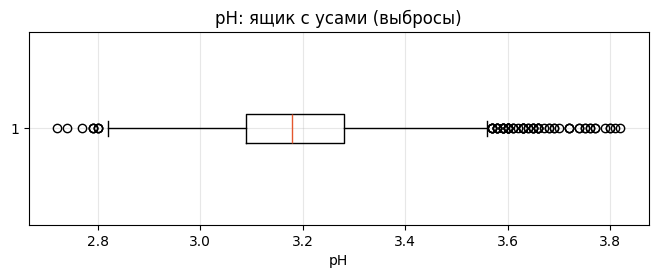

In [ ]:
ph = df["pH"]
desc = pd.DataFrame({"pH": {
    "n": ph.count(), "среднее": ph.mean(), "медиана": ph.median(),
    "мода": ph.mode()[0], "std": ph.std(), "min": ph.min(), "max": ph.max(),
    "Q1": ph.quantile(0.25), "Q3": ph.quantile(0.75),
    "асимметрия": ph.skew(), "эксцесс": ph.kurt()}})
print(desc.round(4))

plt.figure(figsize=(8, 2.5))
plt.boxplot(ph, vert=False)
plt.xlabel("pH")
plt.title("pH: ящик с усами (выбросы)")
plt.show()

**Выводы по описательным статистикам:** среднее (3.188) и медиана (3.18) почти совпадают, асимметрия 0.46 (небольшая положительная, правый хвост чуть длиннее левого), эксцесс 0.53 (немного больше нуля: пик чуть острее и хвосты чуть тяжелее, чем у нормального). На ящике видно, что выбросы есть с обеих сторон: границы усов по правилу 1.5·IQR равны 2.805 и 3.565 (Q1 = 3.09, Q3 = 3.28, IQR = 0.19), а min = 2.72 и max = 3.82 лежат за ними, при этом справа хвост длиннее. Таких крайних значений сравнительно немного на фоне 4898 наблюдений. Выбросы я оставляю, потому что значения 2.7–3.8 лежат в реальном диапазоне pH вина и не похожи на ошибки измерения, а если их убрать, то обрежется хвост, который мы как раз моделируем (лог-нормальное лучше нормального именно из-за хвоста).

#### Форма распределения: гистограмма, Q-Q график, Шапиро-Уилк

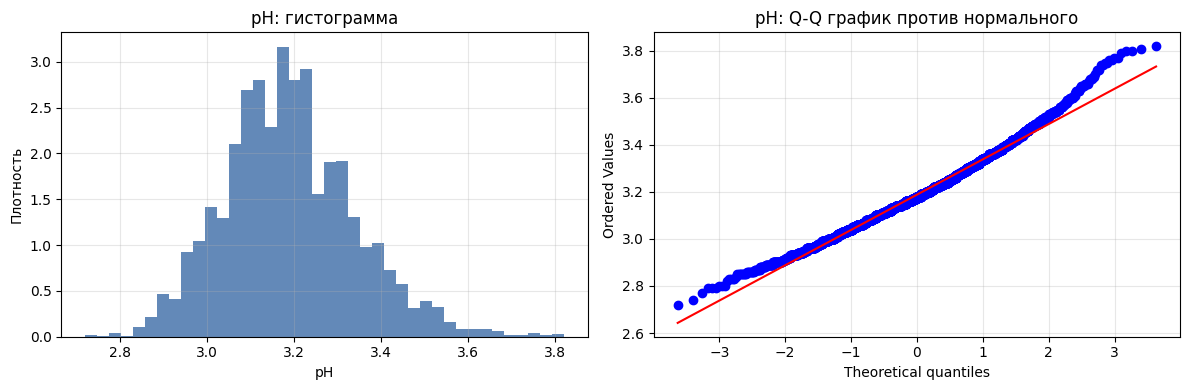

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["pH"], bins=40, density=True)
axes[0].set_title("pH: гистограмма")
axes[0].set_xlabel("pH")
axes[0].set_ylabel("Плотность")

stats.probplot(df["pH"], dist="norm", plot=axes[1])
axes[1].set_title("pH: Q-Q график против нормального")

plt.tight_layout()
plt.show()

In [ ]:
stat, p = stats.shapiro(df["pH"])
print("Статистика Шапиро-Уилка:", stat)
print("p-value:", p)

Статистика Шапиро-Уилка: 0.9880964981563648
p-value: 6.505518567470481e-20


**Q-Q график:** в центре точки лежат на прямой, на правом конце уходят вверх, то есть правый хвост у pH тяжелее, чем у нормального распределения: высокие значения pH встречаются чаще, чем предсказывает нормальный закон. Это согласуется с положительной асимметрией 0.46 и с отвергнутой нормальностью по Шапиро-Уилку.

#### Подбор распределения: нормальное и лог-нормальное

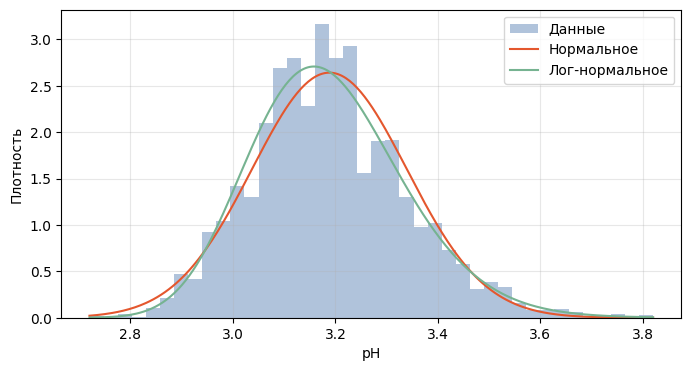

Нормальное: mu = 3.1882666394446715 , sigma = 0.15098518431212068
Лог-нормальное: shape = 0.13634791317752573 , loc = 2.0877008414300846 , scale = 1.0903765817054785


In [ ]:
x = np.linspace(df["pH"].min(), df["pH"].max(), 300)

mu, sigma = stats.norm.fit(df["pH"])
shape, loc, scale = stats.lognorm.fit(df["pH"])

plt.figure(figsize=(8, 4))
plt.hist(df["pH"], bins=40, density=True, alpha=0.5, label="Данные")
plt.plot(x, stats.norm.pdf(x, mu, sigma), label="Нормальное")
plt.plot(x, stats.lognorm.pdf(x, shape, loc, scale), label="Лог-нормальное")
plt.xlabel("pH")
plt.ylabel("Плотность")
plt.legend()
plt.show()

print("Нормальное: mu =", mu, ", sigma =", sigma)
print("Лог-нормальное: shape =", shape, ", loc =", loc, ", scale =", scale)

In [ ]:
ll_norm = np.sum(stats.norm.logpdf(df["pH"], mu, sigma))
ll_logn = np.sum(stats.lognorm.logpdf(df["pH"], shape, loc, scale))

aic_norm = 2 * 2 - 2 * ll_norm
aic_logn = 2 * 3 - 2 * ll_logn

print("AIC нормальное:", aic_norm)
print("AIC лог-нормальное:", aic_logn)

print(stats.kstest(df["pH"], "norm", args=(mu, sigma)))
print(stats.kstest(df["pH"], "lognorm", args=(shape, loc, scale)))

AIC нормальное: -4616.136762839567
AIC лог-нормальное: -4765.473072519412
KstestResult(statistic=np.float64(0.049265405769459814), pvalue=np.float64(9.036547927625019e-11), statistic_location=np.float64(3.2), statistic_sign=np.int8(1))
KstestResult(statistic=np.float64(0.024630796701975932), pvalue=np.float64(0.005160058220838705), statistic_location=np.float64(3.1), statistic_sign=np.int8(-1))


**Выводы по распределению pH**

Тест Шапиро-Уилка дал p = 6.5·10⁻²⁰, значит, нормальность отвергаем.
При этом W = 0.988, то есть очень близко к 1.
Расстояние KS у нормального 0.049, у лог-нормального 0.025, а AIC
у лог-нормального ниже (−4765 против −4616), поэтому лог-нормальное
описывает данные лучше. Скорее всего, из-за правого хвоста.
На графике разница между кривыми небольшая, и ни одно распределение
не подходит идеально.


**Оговорки к тесту KS и к параметрам:**
- Параметры распределений я подбирала по тем же данным, на которых потом считала KS, поэтому p-value получается завышенным. Сравниваю распределения друг с другом (AIC и расстояние KS), а не смотрю на p по отдельности.
- У лог-нормального параметр loc = 2.09: это сдвинутое лог-нормальное с тремя параметрами, поэтому для сравнения использован AIC (он штрафует за число параметров).
- Итоговый выбор распределения для pH: лог-нормальное со сдвигом (loc = 2.09), потому что у него ниже AIC (−4765 против −4616) и меньше расстояние KS (0.025 против 0.049), но это лишь лучшее из двух кандидатов: p-value KS малы у обоих, и идеально pH не описывает ни одно. Для генератора во втором спринте беру: лог-нормальное с параметрами shape = 0.136, loc = 2.088, scale = 1.090 (нормальное N(3.188; 0.151) оставляю как запасной вариант для сравнения).

#### Математическое описание распределения

**1. Нормальное распределение.** Плотность

$$f(x)=\frac{1}{\sigma\sqrt{2\pi}}\exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right),\quad x\in\mathbb{R}.$$

Параметр $\mu$ — центр распределения, он же среднее, медиана и мода. Параметр $\sigma$ — стандартное отклонение, оно задаёт ширину колокола: в пределах $\mu\pm\sigma$ лежит около 68% значений. Для pH получилось $\mu = 3.188$, $\sigma = 0.151$.

**2. Лог-нормальное распределение со сдвигом.** Величина $X$ имеет такое распределение, если $\ln(X-\theta)$ нормальна. Плотность

$$f(x)=\frac{1}{(x-\theta)\,s\sqrt{2\pi}}\exp\left(-\frac{\left(\ln(x-\theta)-m\right)^2}{2s^2}\right),\quad x>\theta.$$

Здесь $\theta$ (в `scipy` это `loc`) — сдвиг: левая граница, левее которой значений нет. $m=\ln(\text{scale})$ — среднее, а $s$ (`shape`) — стандартное отклонение величины $\ln(X-\theta)$. Для pH: $s = 0.136$, $\theta = 2.088$, $\text{scale} = 1.090$, то есть $m=\ln 1.090\approx 0.087$.

**3. Откуда берутся эти распределения.** Нормальное возникает по центральной предельной теореме: если величина — сумма многих небольших независимых воздействий, то она близка к нормальной. Лог-нормальное возникает из того же рассуждения для произведения: если величина — произведение многих небольших положительных множителей, то её логарифм (сумма логарифмов) близок к нормальному, а сама величина лог-нормальна.

**4. Особенности.** Нормальное симметрично, определено на всей прямой, асимметрия равна 0, эксцесс (избыточный) равен 0. Лог-нормальное определено только при $x>\theta$ и скошено вправо, у него длинный правый хвост. Моменты (для $X-\theta$): $\mathbb{E}[X]=\theta+e^{m+s^2/2}$, асимметрия $(e^{s^2}+2)\sqrt{e^{s^2}-1}$. Подставив мои параметры, получаю среднее $\approx 3.188$ (в данных 3.188) и асимметрию $\approx 0.41$ (в данных 0.46), так что подобранное распределение воспроизводит и центр, и скошенность.

**5. Почему это подходит для pH.** pH — это $-\lg[\mathrm{H}^+]$, то есть уже логарифм концентрации, а на кислотность вина влияет много факторов (сорт, зрелость, брожение, соли и кислоты), действующих вместе. Поэтому разумно ожидать, что pH близок к нормальному (если pH нормален, то сама концентрация $[\mathrm{H}^+]=10^{-\mathrm{pH}}$ лог-нормальна). Реальный pH слегка скошен вправо (асимметрия 0.46), и сдвинутое лог-нормальное описывает этот хвост лучше нормального (AIC −4765 против −4616). При этом химического смысла у параметра $\theta = 2.09$ я не вижу, это просто подгонка формы, и ни одно из распределений не подходит идеально (KS отвергает оба).

**6. Как оценила параметры.** Методом максимального правдоподобия: нахожу параметры, которые максимизируют $\sum_i \ln f(x_i;\,\text{параметры})$. Для нормального ответ в явном виде: $\hat\mu=\bar x$, $\hat\sigma^2=\frac1n\sum(x_i-\bar x)^2$. Для лог-нормального с тремя параметрами формулы нет, `stats.lognorm.fit` ищет максимум численно. Модели сравнивала по $AIC=2k-2\ln L$, где $k$ — число параметров (2 и 3), потому что он штрафует за усложнение.

**7. Литература.**
- Cortez P., Cerdeira A., Almeida F., Matos T., Reis J. Modeling wine preferences by data mining from physicochemical properties. Decision Support Systems, 2009 (источник данных).
- Limpert E., Stahel W.A., Abbt M. Log-normal distributions across the sciences: keys and clues. BioScience, 2001.
- Гмурман В.Е. Теория вероятностей и математическая статистика.
- Akaike H. A new look at the statistical model identification. IEEE Trans. Automatic Control, 1974.
- Документация SciPy: `scipy.stats.norm`, `scipy.stats.lognorm`.


#### Нормализация (пункт 2.4)

Среднее после стандартизации: -1.1837543331568839e-15
Std после стандартизации: 1.0000000000000027
Асимметрия до и после: 0.4577825459180807 0.4577825459180842


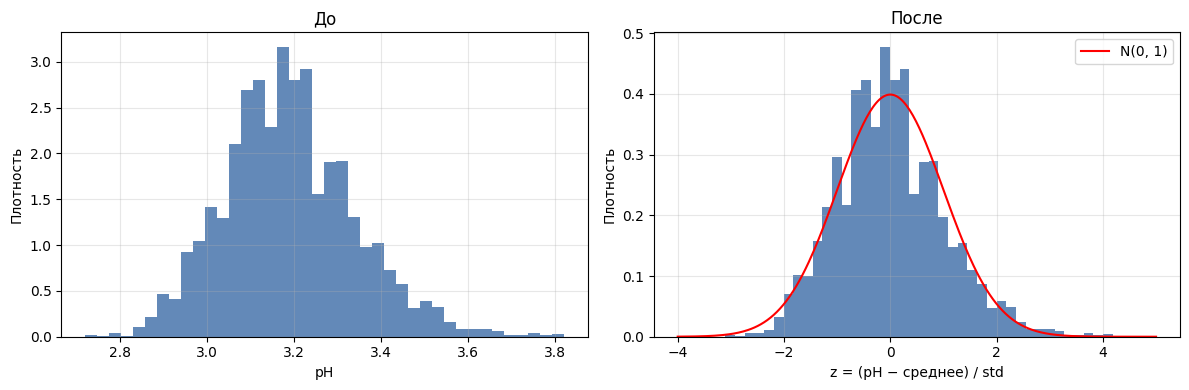

In [ ]:
ph = df["pH"]
ph_z = (ph - ph.mean()) / ph.std()

print("Среднее после стандартизации:", ph_z.mean())
print("Std после стандартизации:", ph_z.std())
print("Асимметрия до и после:", ph.skew(), ph_z.skew())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(ph, bins=40, density=True)
axes[0].set_xlabel("pH")
axes[0].set_ylabel("Плотность")
axes[0].set_title("До")

axes[1].hist(ph_z, bins=40, density=True)
xs = np.linspace(-4, 5, 300)
axes[1].plot(xs, stats.norm.pdf(xs), color="red", label="N(0, 1)")
axes[1].set_xlabel("z = (pH − среднее) / std")
axes[1].set_ylabel("Плотность")
axes[1].set_title("После")
axes[1].legend()

plt.tight_layout()
plt.show()

**Вывод по нормализации:**
После стандартизации $z = (x - \bar{x})/s$ среднее равно 0 (порядка 10⁻¹⁵, это ошибка округления), std равно 1. Асимметрия до и после одинаковая (0.4578): стандартизация меняет только шкалу, но не форму. Поэтому pH после неё не становится нормальным, это видно по правому хвосту и более высокому пику относительно $N(0,1)$. Мотивация: pH, residual sugar и alcohol измерены в разных единицах (безразмерная величина, г/л, % об.), и после стандартизации их можно сравнивать в одной шкале. Кроме того, z-значения удобно сопоставлять со стандартным $N(0,1)$, а для генератора обратное преобразование $x = s \cdot z + \bar{x}$ возвращает значения в исходные единицы.


### Independence & Estimations


#### Независимость (пункт 2.2)

pH и alcohol: Пирсон r = 0.121 (p = 1.5e-17), Спирмен rho = 0.149 (p = 1.1e-25)
pH и residual sugar: Пирсон r = -0.194 (p = 8.4e-43), Спирмен rho = -0.180 (p = 5.9e-37)
alcohol и residual sugar: Пирсон r = -0.451 (p = 1.2e-243), Спирмен rho = -0.445 (p = 3.1e-237)


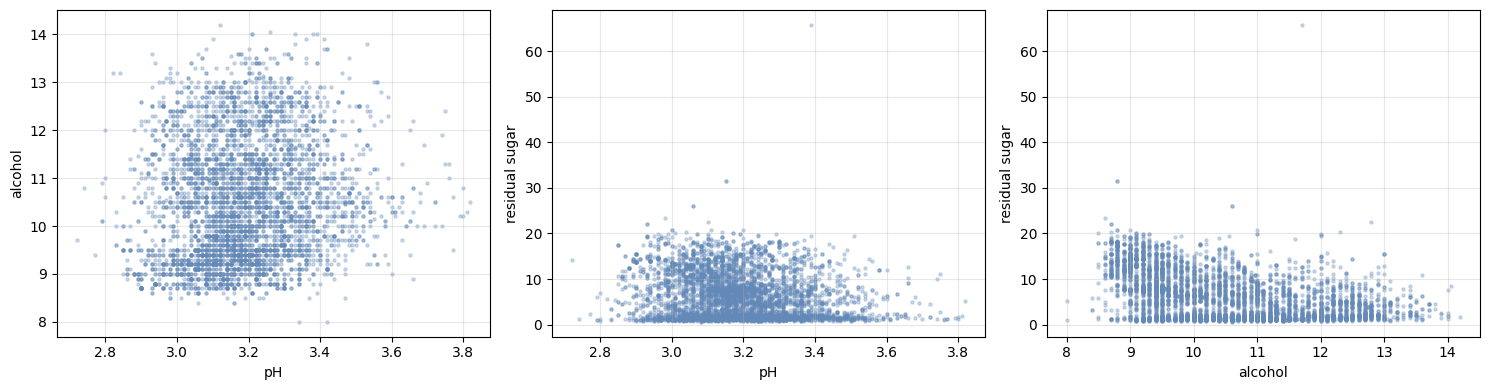

In [ ]:
pairs = [("pH", "alcohol"), ("pH", "residual sugar"), ("alcohol", "residual sugar")]

for a, b in pairs:
    r, p_r = stats.pearsonr(df[a], df[b])
    rho, p_s = stats.spearmanr(df[a], df[b])
    print(f"{a} и {b}: Пирсон r = {r:.3f} (p = {p_r:.2g}), Спирмен rho = {rho:.3f} (p = {p_s:.2g})")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (a, b) in zip(axes, pairs):
    ax.scatter(df[a], df[b], s=5, alpha=0.3)
    ax.set_xlabel(a)
    ax.set_ylabel(b)
plt.tight_layout()
plt.show()

**Независимость величин**

Я проверила три пары величин, измеренных на одном и том же вине.
Самая независимая пара: pH и alcohol (r = 0.12), на графике это
бесформенное облако без наклона.
Самая связанная пара: alcohol и residual sugar (r = −0.45), на графике
облако идёт вниз: чем больше спирта, тем меньше сахара.
Пара pH и residual sugar дала r = −0.19, связь слабая.
Все p-value очень маленькие (от 10⁻¹⁷ до 10⁻²⁴³), но это потому, что
наблюдений 4898, и тест замечает даже очень слабую связь. Поэтому я
смотрю на размер коэффициента, а не только на p.
Пирсон и Спирмен получились почти одинаковыми, значит, хвост сахара и
выбросы корреляцию не искажают.
Вывод: величины нельзя считать полностью независимыми, но зависимость
между pH и спиртом пренебрежимо слабая, а между спиртом и сахаром
умеренная.
Химическая причина: при брожении дрожжи превращают сахар в спирт, и
чем полнее брожение, тем больше спирта и меньше остаточного сахара.

Критерий χ² для пары alcohol и residual sugar приведён один раз в разделе «Независимость трёх величин» (перед Lab resume).

#### Состоятельность оценок (пункт 2.3)

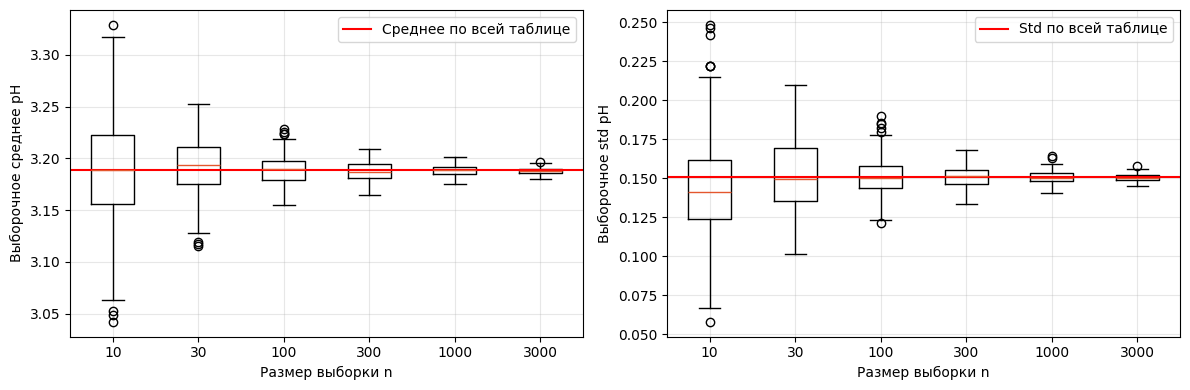

In [ ]:
rng = np.random.default_rng(SEED)

true_mean = df["pH"].mean()
true_std = df["pH"].std()

sizes = [10, 30, 100, 300, 1000, 3000]
n_repeats = 200

means = []
stds = []
for n in sizes:
    m_list = []
    s_list = []
    for _ in range(n_repeats):
        sample = rng.choice(df["pH"], size=n, replace=True)
        m_list.append(sample.mean())
        s_list.append(sample.std(ddof=1))
    means.append(m_list)
    stds.append(s_list)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot(means, tick_labels=sizes)
axes[0].axhline(true_mean, color="red", label="Среднее по всей таблице")
axes[0].set_xlabel("Размер выборки n")
axes[0].set_ylabel("Выборочное среднее pH")
axes[0].legend()

axes[1].boxplot(stds, tick_labels=sizes)
axes[1].axhline(true_std, color="red", label="Std по всей таблице")
axes[1].set_xlabel("Размер выборки n")
axes[1].set_ylabel("Выборочное std pH")
axes[1].legend()

plt.tight_layout()
plt.show()

**Состоятельность**

Выборки здесь взяты с возвращением (как и у остальных величин), поэтому «сужение» ящиков не объясняется тем, что выборка почти совпадает со всей таблицей.
При n = 10 выборочное среднее pH лежало примерно от 3.06 до 3.32, при n = 3000 примерно от 3.18 до 3.20. С ростом n ящики сужаются вокруг красной линии, то же происходит со стандартным отклонением.
«Истинные» значения в эксперименте — это статистики 4898 строк, а не всех белых вин.

**Дополнение к выводу:** выборочное стандартное отклонение при малых $n$ в среднем немного ниже значения по всей таблице. По мере увеличения выборки это отклонение уменьшается; отдельная численная оценка смещения здесь не рассчитывается.

#### Выборки с возвращением и без (пункт 2.5)

In [ ]:
rng = np.random.default_rng(SEED)
n = N_SAMPLE

sample_no_repl = rng.choice(df["pH"], size=n, replace=False)
sample_repl = rng.choice(df["pH"], size=n, replace=True)

result = pd.DataFrame({
    "Вся таблица": [df["pH"].mean(), df["pH"].std(), df["pH"].median(), df["pH"].skew()],
    "Без возвращения": [sample_no_repl.mean(), sample_no_repl.std(ddof=1), np.median(sample_no_repl), stats.skew(sample_no_repl)],
    "С возвращением": [sample_repl.mean(), sample_repl.std(ddof=1), np.median(sample_repl), stats.skew(sample_repl)],
}, index=["Среднее", "Std", "Медиана", "Асимметрия"])

print(result.round(4))

            Вся таблица  Без возвращения  С возвращением
Среднее          3.1883           3.1909          3.2007
Std              0.1510           0.1544          0.1475
Медиана          3.1800           3.1800          3.1800
Асимметрия       0.4578           0.5170          0.5695


**По одной выборке из 500:** среднее, std и медиана обеих выборок близки к значениям по всей таблице. Асимметрия в выборках выше (0.52 и 0.57 против 0.46). Разницу между способами по одной выборке делать нельзя, она зависит от seed, поэтому ниже повторяю 1000 раз.

In [ ]:
rng = np.random.default_rng(SEED)
n = N_SAMPLE
reps = 1000

m_no = [rng.choice(df["pH"], size=n, replace=False).mean() for _ in range(reps)]
m_yes = [rng.choice(df["pH"], size=n, replace=True).mean() for _ in range(reps)]

print("Среднее по таблице:", df["pH"].mean())
print("Без возвращения: среднее средних =", np.mean(m_no), ", std средних =", np.std(m_no, ddof=1))
print("С возвращением:  среднее средних =", np.mean(m_yes), ", std средних =", np.std(m_yes, ddof=1))

N = len(df)
sigma_pop = df["pH"].std(ddof=0)
print("Теория с возвращением:", sigma_pop / np.sqrt(n))
print("Теория без возвращения:", sigma_pop / np.sqrt(n) * np.sqrt((N - n) / (N - 1)))

Среднее по таблице: 3.1882666394446715
Без возвращения: среднее средних = 3.18830516 , std средних = 0.006215137625999139
С возвращением:  среднее средних = 3.1885384999999995 , std средних = 0.006774398705998024
Теория с возвращением: 0.006752262714344729
Теория без возвращения: 0.006398996782587604


**С возвращением и без**

С возвращением: вытащили элемент, записали результат и положили обратно.
Состав совокупности не меняется, поэтому испытания независимы, а один
и тот же элемент может попасть в выборку несколько раз.
Без возвращения: вытащенный элемент назад не кладётся, совокупность
«уменьшается», испытания зависимы, повторов быть не может.

В моём эксперименте на 1000 повторов разброс средних был 0.0062
(без возвращения) и 0.0068 (с возвращением). Без возвращения он меньше,
потому что одно и то же вино не может попасть в выборку дважды, и
выборки меньше отличаются друг от друга. Теория дала 0.0064 и 0.0068,
то есть сходится с экспериментом.

#### Проверка гипотезы (пункт 2.7)

In [ ]:
rng = np.random.default_rng(SEED)
sample = rng.choice(df["pH"], size=N_SAMPLE, replace=False)

t, p = stats.ttest_1samp(sample, popmean=3.2)
print("Среднее выборки:", sample.mean())
print("t =", t, ", p =", p)

# Тот же тест на всей таблице
t_all, p_all = stats.ttest_1samp(df["pH"], popmean=3.2)
print("На всей таблице: t =", t_all, ", p =", p_all)

Среднее выборки: 3.1908999999999996
t = -1.3176099190086636 , p = 0.1882388837444747
На всей таблице: t = -5.438174447136783 , p = 5.6444547629983836e-08


**Проверка гипотезы**

$H_0$: среднее pH равно 3.2, $H_1$: среднее pH не равно 3.2, $\alpha = 0.05$.
На выборке из 500 вин: среднее = 3.1909, t = −1.32, p = 0.188 > 0.05, значит $H_0$ отвергнуть нельзя. Это не доказывает, что среднее равно 3.2, просто данных недостаточно против него.
На всей таблице (n = 4898): t = −5.44, p = 5.6·10⁻⁸, $H_0$ отвергаем.
Результаты разные, потому что $t = (\bar{x} - \mu_0)\sqrt{n}/s$ растёт с n: при n = 500 разница в 0.01 теряется в шуме, при n = 4898 уже заметна.
Разница между 3.188 и 3.2 составляет около 0.012 единицы pH — это мало по сравнению с разбросом данных ($s\approx0.151$). Однако практическую значимость нельзя оценить без отдельного критерия или характеристик измерительного прибора.
Условие применимости: pH формально не нормальный, но при n = 500 среднее близко к нормальному по ЦПТ.
Устойчивость: разница между средним по таблице и 3.2 составляет около 0.012, а стандартная ошибка среднего для выборки из 500 наблюдений — около 0.0068. Поэтому результат проверки на отдельной случайной выборке может зависеть от её состава. Здесь приведён воспроизводимый результат для seed = 42; для оценки устойчивости решения потребовалось бы повторить тест на нескольких независимо сформированных выборках.

In [ ]:
# Гипотеза: pH у вин с высокой и низкой оценкой качества различается
high = df.loc[df["quality"] >= 7, "pH"]
low = df.loc[df["quality"] <= 5, "pH"]
u, p_u = stats.mannwhitneyu(high, low, alternative="two-sided")
rbc = 2 * u / (len(high) * len(low)) - 1   # ранговая бисериальная корреляция (размер эффекта)
print("Вин с quality >= 7:", len(high), ", с quality <= 5:", len(low))
print("Медиана pH: высокое качество =", high.median(), ", низкое =", low.median())
print("U =", u, ", p =", p_u, ", размер эффекта (r_rb) =", round(rbc, 3))

Вин с quality >= 7: 1060 , с quality <= 5: 1640
Медиана pH: высокое качество = 3.2 , низкое = 3.16
U = 1022099.0 , p = 1.0627230508442323e-14 , размер эффекта (r_rb) = 0.176


**Дополнительная гипотеза: различается ли pH у вин разного качества?**

Сравниваем образцы с оценкой `quality ≥ 7` ($n=1060$) и `quality ≤ 5` ($n=1640$).
$H_0$: распределения pH в двух группах одинаковы; $H_1$: различаются; $\alpha=0.05$.
Использован двусторонний критерий Манна — Уитни, не требующий нормальности распределений.

Медианный pH в группе высокого качества — **3.20**, в группе низкого качества — **3.16**.
Получено $U=1022099$, $p=1.06\cdot10^{-14}$, ранговая бисериальная корреляция $r_{rb}=0.176$.
Нулевая гипотеза отвергается: различие статистически значимо, однако **размер эффекта невелик**.
Из такого сравнения нельзя сделать вывод о причинном влиянии pH на качество вина.


### Итоговый вывод по pH
pH белого вина можно считать случайной величиной: он зависит от множества заранее неизвестных факторов (сорт, урожай, брожение), его значение для случайно выбранного образца заранее неизвестно и измеряется с погрешностью. Нормальным его считать нельзя (Шапиро-Уилк: p = 6.5·10⁻²⁰, хотя W = 0.988 близко к 1), потому что правый хвост тяжелее нормального. Из двух кандидатов лучше лог-нормальное со сдвигом (AIC −4765 против −4616, KS 0.025 против 0.049), его я и беру для генератора, помня, что идеально не подходит ни одно. Оценки среднего и std состоятельны: с ростом размера выборки ящики сужаются вокруг значений по всей таблице (std при малых n немного занижен). pH слабо связан со спиртом (r = 0.12) и сахаром (r = −0.19), в отличие от пары спирт–сахар (r = −0.45), поэтому с точки зрения генератора pH можно моделировать почти отдельно. Проверка гипотезы $H_0$: среднее = 3.2 на выборке из 500 вин не отвергла её (p = 0.188), а на всей таблице отвергла (p = 5.6·10⁻⁸), но разница в 0.012 практически ничтожна, и вывод на одной выборке неустойчив. В целом белые вина в датасете имеют узкий диапазон кислотности (pH 2.72–3.82, std 0.15), то есть довольно однородны по этому показателю.



## Random Variable 02 (residual sugar)


### Description
**Случайная величина:** массовая концентрация остаточного сахара в белом вине (residual sugar). Используем те же 4898 наблюдений из Wine Quality (белые вина), что и для pH и alcohol.

| Характеристика | Значение |
|---|---|
| Единицы измерения | г/л |
| Физический тип | непрерывная, неотрицательная |
| Диапазон в данных | 0.6–65.8 г/л |
| Среднее | 6.3914 г/л |
| Медиана | 5.2 г/л |

**Почему это случайная величина.** Для случайно выбранного вина концентрация сахара зависит от исходного состава винограда, степени зрелости, активности дрожжей, режима и момента остановки брожения. Не зная условий производства и измерений, точное значение заранее предсказать нельзя. Измерение имеет конечную точность, поэтому в таблице возможны повторения округлённых значений, хотя исходная физическая величина непрерывна.

**Вывод:** остаточный сахар можно анализировать как случайную величину.

In [ ]:
residual_sugar = df["residual sugar"].dropna()
sugar_values = residual_sugar.to_numpy()
print("Число наблюдений:", len(sugar_values))
print("Уникальные записанные значения:", residual_sugar.nunique())
print("Наиболее частые значения (г/л):")
print(residual_sugar.value_counts().head(10).to_string())

Число наблюдений: 4898
Уникальные записанные значения: 310
Наиболее частые значения (г/л):
residual sugar
1.2    187
1.4    184
1.6    165
1.3    147
1.1    146
1.5    142
1.7     99
1.8     99
1.0     93
2.0     79



### EDA & Distribution


n             4898.0000
среднее          6.3914
медиана          5.2000
мода             1.2000
std              5.0721
min              0.6000
max             65.8000
Q1               1.7000
Q3               9.9000
асимметрия       1.0771
эксцесс          3.4698
Границы по правилу 1.5 IQR: -10.60 ... 22.20 г/л
Число формальных выбросов: 7


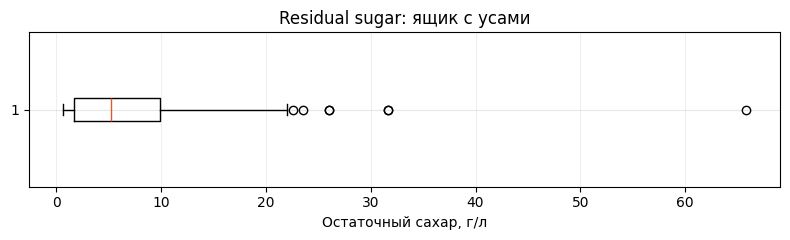

In [ ]:
sugar_description = pd.Series({
    "n": residual_sugar.count(),
    "среднее": residual_sugar.mean(),
    "медиана": residual_sugar.median(),
    "мода": residual_sugar.mode().iloc[0],
    "std": residual_sugar.std(ddof=1),
    "min": residual_sugar.min(),
    "max": residual_sugar.max(),
    "Q1": residual_sugar.quantile(.25),
    "Q3": residual_sugar.quantile(.75),
    "асимметрия": residual_sugar.skew(),
    "эксцесс": residual_sugar.kurt()
})
print(sugar_description.round(4).to_string())
sugar_q1, sugar_q3 = residual_sugar.quantile([.25, .75])
sugar_iqr = sugar_q3 - sugar_q1
sugar_lower = sugar_q1 - 1.5 * sugar_iqr
sugar_upper = sugar_q3 + 1.5 * sugar_iqr
sugar_outliers = ((residual_sugar < sugar_lower) | (residual_sugar > sugar_upper)).sum()
print(f"Границы по правилу 1.5 IQR: {sugar_lower:.2f} ... {sugar_upper:.2f} г/л")
print("Число формальных выбросов:", int(sugar_outliers))

plt.figure(figsize=(8, 2.5))
plt.boxplot(sugar_values, vert=False)
plt.xlabel("Остаточный сахар, г/л")
plt.title("Residual sugar: ящик с усами")
plt.grid(axis="x", alpha=.2)
plt.tight_layout()
plt.show()

**Интерпретация.** Среднее **6.3914 г/л** выше медианы **5.2 г/л**. Стандартное отклонение **5.0721 г/л**, асимметрия **1.0771** (длинный правый хвост), эксцесс 3.4698 (более тяжёлые хвосты относительно нормального распределения). Q1 = **1.7** г/л, Q3 = **9.9** г/л, поэтому IQR = 8.2 г/л и верхняя граница по правилу 1.5·IQR составляет **22.2 г/л**. Значения выше неё являются формальными выбросами, но не обязательно ошибками: сладкие вина могут содержать намного больше остаточного сахара. Такие наблюдения сохраняем, поскольку они важны для формы хвоста.

#### Форма распределения, Q–Q график и тест Шапиро–Уилка

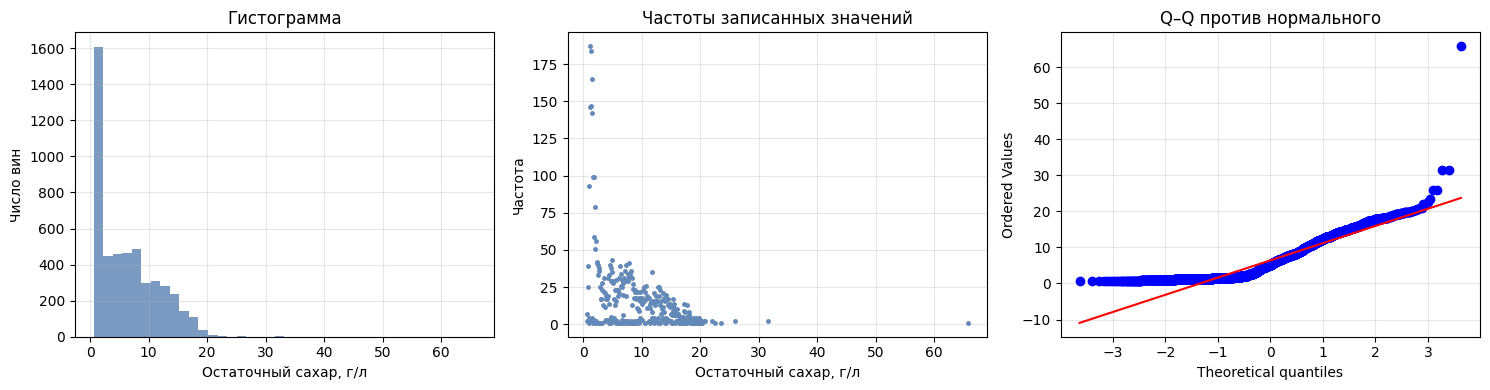

Шапиро–Уилк: W=0.884569; p=2.821e-51


In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].hist(sugar_values, bins=40, color="#6389B8", alpha=.85)
axs[0].set(xlabel="Остаточный сахар, г/л", ylabel="Число вин", title="Гистограмма")

sugar_freq = residual_sugar.value_counts().sort_index()
axs[1].plot(sugar_freq.index, sugar_freq.values, ".", markersize=5)
axs[1].set(xlabel="Остаточный сахар, г/л", ylabel="Частота", title="Частоты записанных значений")

stats.probplot(sugar_values, dist="norm", plot=axs[2])
axs[2].set_title("Q–Q против нормального")
plt.tight_layout()
plt.show()

sugar_w, sugar_p_shapiro = stats.shapiro(sugar_values)
print(f"Шапиро–Уилк: W={sugar_w:.6f}; p={sugar_p_shapiro:.3e}")

Гистограмма показывает концентрацию наблюдений при относительно небольшом содержании сахара и длинный хвост вправо до **65.8 г/л.** График частот позволяет увидеть повторения значений, записанных с ограниченной точностью. На Q–Q графике выраженное отклонение точек от прямой (особенно справа) показывает, что нормальное распределение плохо описывает хвост. По тесту Шапиро–Уилка при **p < 0.05** отвергаем гипотезу о точной нормальности (точное значение p выводится кодом). Важно, что при n = **4898** тест чувствителен даже к сравнительно небольшим отклонениям; форму дополнительно оцениваем визуально и сравнением моделей.

#### Подбор распределения: лог-нормальное, гамма, Вейбулла и экспоненциальное

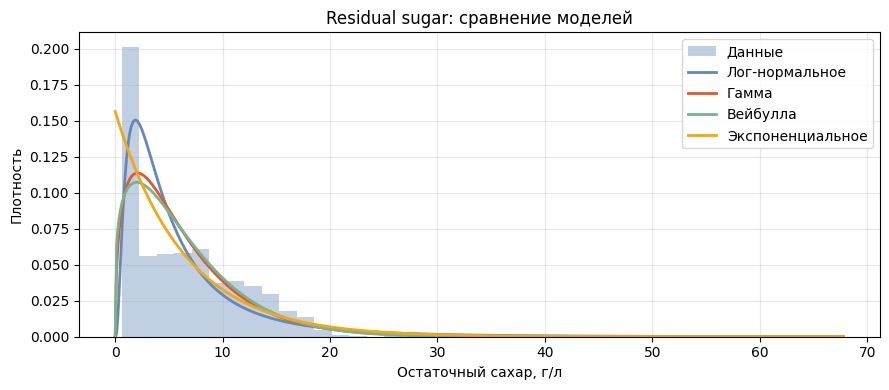

          Модель  k        AIC   KS D
           Гамма  2 27559.5859 0.1198
        Вейбулла  2 27584.8272 0.1180
  Лог-нормальное  2 27611.8500 0.1108
Экспоненциальное  1 27969.1457 0.1291
Лучшая модель по AIC: Гамма
Параметры (в порядке SciPy): (1.4814063452349577, 0, np.float64(4.314423847155702))


In [ ]:
# Все четыре кандидата поддерживают x > 0; loc=0 фиксируем,
# чтобы модель не приписывала отрицательные значения концентрации.
sugar_models = {
    "Лог-нормальное": stats.lognorm,
    "Гамма": stats.gamma,
    "Вейбулла": stats.weibull_min,
    "Экспоненциальное": stats.expon,
}
sugar_fitted = {}
sugar_results = []
sugar_x = np.linspace(0, sugar_values.max() + 2, 550)

plt.figure(figsize=(9, 4))
plt.hist(sugar_values, bins=40, density=True, color="#6389B8", alpha=.40, label="Данные")
for name, model in sugar_models.items():
    params = model.fit(sugar_values, floc=0)
    sugar_fitted[name] = params
    ll = np.sum(model.logpdf(sugar_values, *params))
    # Параметр loc=0 задан заранее, не оценивается по данным.
    k = len(params) - 1
    aic = 2 * k - 2 * ll
    ks_d = stats.kstest(sugar_values, model.cdf, args=params).statistic
    sugar_results.append([name, k, aic, ks_d])
    plt.plot(sugar_x, model.pdf(sugar_x, *params), linewidth=2, label=name)

plt.xlabel("Остаточный сахар, г/л")
plt.ylabel("Плотность")
plt.title("Residual sugar: сравнение моделей")
plt.legend()
plt.tight_layout()
plt.show()

sugar_fit_table = pd.DataFrame(sugar_results, columns=["Модель", "k", "AIC", "KS D"]).sort_values("AIC")
print(sugar_fit_table.round(4).to_string(index=False))
sugar_best_model = sugar_fit_table.iloc[0]["Модель"]
print("Лучшая модель по AIC:", sugar_best_model)
print("Параметры (в порядке SciPy):", sugar_fitted[sugar_best_model])

#### Сравнение распределений

Для сравнения моделей используются критерии **AIC** и **KS D**: чем меньше их значения, тем лучше модель описывает данные. Наиболее подходящее распределение выбирается по минимальному AIC.

Для всех моделей принято `loc=0`. При этом логнормальное, гамма-распределение и распределение Вейбулла имеют по два оцениваемых параметра, экспоненциальное — один.

Поскольку данные могут содержать несколько пиков и выбросы, выбранная модель является приближением. Для более точного воспроизведения исходного распределения можно использовать эмпирический метод.

**Результаты сравнения моделей.**

| Распределение | k | AIC | KS D |
|---|---:|---:|---:|
| Гамма | 2 | **27559.6** | 0.1198 |
| Вейбулла | 2 | 27584.8 | 0.1180 |
| Лог-нормальное | 2 | 27611.9 | **0.1108** |
| Экспоненциальное | 1 | 27969.1 | 0.1291 |

По AIC лучшая модель — гамма (параметры формы 1.48 и масштаба 4.31 при loc = 0). По расстоянию KS лучшее — лог-нормальное. Критерии расходятся, потому что AIC оценивает правдоподобие всей выборки, а KS — максимальное расхождение функций распределения. При этом все значения KS больше 0.11: ни одна простая гладкая модель сахар не описывает хорошо (у данных пик около 1.2 г/л и «полка» до 20 г/л). Для генератора поэтому разумно рассмотреть эмпирическое квантильное преобразование.


#### Математическая база распределения

**1. Логнормальное распределение**

Если $Y=\ln X$ имеет нормальное распределение, то плотность $X$:

$$
f_{LN}(x)=\frac{1}{xs\sqrt{2\pi}}\exp\left(-\frac{(\ln x-m)^2}{2s^2}\right), \quad x>0
$$

В `scipy.stats.lognorm` параметр `shape` равен $s$, `scale` равен $e^m$, `loc=0`. Распределение имеет правостороннюю асимметрию.

$$
E[X]=e^{m+s^2/2}
$$

**2. Гамма-распределение**

Плотность распределения:

$$
f_G(x)=\frac{x^{k-1}e^{-x/\theta}}{\Gamma(k)\theta^k}, \quad x>0
$$

где $k>0$ — параметр формы (`a` в SciPy), $\theta>0$ — масштаб (`scale`).

$$
E[X]=k\theta, \qquad Var(X)=k\theta^2
$$

Гамма-распределение используется для описания положительных асимметричных величин.

**3. Распределение Вейбулла**

Плотность распределения:

$$
f_W(x)=\frac{k}{\lambda}\left(\frac{x}{\lambda}\right)^{k-1}\exp\left[-\left(\frac{x}{\lambda}\right)^k\right], \quad x>0
$$

где $k>0$ — параметр формы (`c` в SciPy), $\lambda>0$ — масштаб (`scale`).

При $k=1$ распределение становится экспоненциальным. Изменение параметра формы влияет на асимметрию и хвост распределения.

**4. Экспоненциальное распределение**

Плотность распределения:

$$
f_E(x)=\lambda e^{-\lambda x}, \quad x\geq 0
$$

где $\lambda>0$ — параметр интенсивности.

$$
E[X]=\frac{1}{\lambda}
$$

В SciPy `scale=1/λ`. Это однопараметрическая модель с убывающей плотностью.

**Выбор распределений**

Концентрация остаточного сахара неотрицательна, а её распределение имеет правостороннюю асимметрию и может содержать экстремальные значения. Рассмотренные модели позволяют описывать такие данные с разной точностью.

Параметры оцениваются методом максимального правдоподобия, а сравнение моделей проводится по критериям **AIC** и **KS D**.


#### Нормализация

Среднее после стандартизации: -1.0444891174913682e-16
Std после стандартизации: 1.0000000000000002
Асимметрия до и после: 1.0770937564240868 1.077093756424087


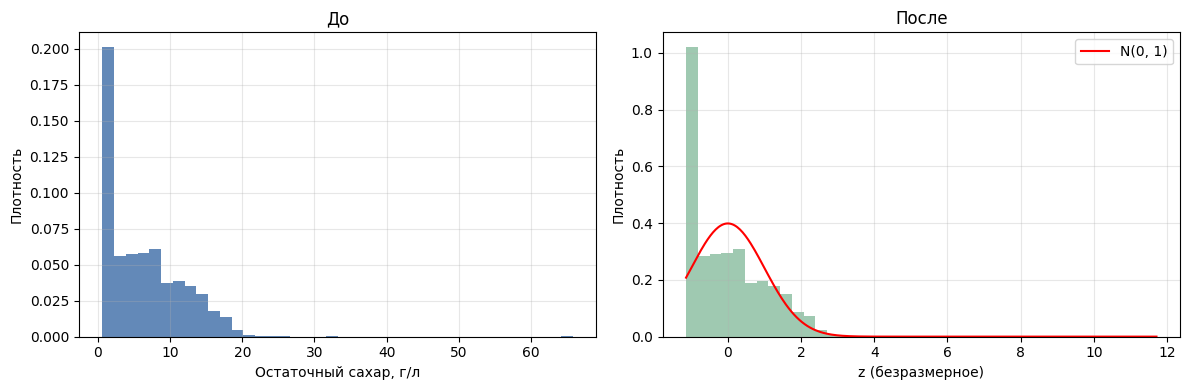

In [ ]:
sugar_z = (residual_sugar - residual_sugar.mean()) / residual_sugar.std(ddof=1)
print("Среднее после стандартизации:", sugar_z.mean())
print("Std после стандартизации:", sugar_z.std(ddof=1))
print("Асимметрия до и после:", residual_sugar.skew(), sugar_z.skew())

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].hist(sugar_values, bins=40, density=True, color="#6389B8")
axs[0].set(xlabel="Остаточный сахар, г/л", ylabel="Плотность", title="До")
axs[1].hist(sugar_z, bins=40, density=True, color="#76B391", alpha=.7)
sugar_z_grid = np.linspace(sugar_z.min(), sugar_z.max(), 350)
axs[1].plot(sugar_z_grid, stats.norm.pdf(sugar_z_grid), color="red", label="N(0, 1)")
axs[1].set(xlabel="z (безразмерное)", ylabel="Плотность", title="После")
axs[1].legend()
plt.tight_layout()
plt.show()

Стандартизация выполняется по формуле:

$$
z_i = \frac{x_i - \bar{x}}{s}
$$

После стандартизации среднее значение становится равным **0**, а выборочное стандартное отклонение — **1**.

Асимметрия остаётся **1.0771**, поэтому распределение сохраняет правостороннюю асимметрию и не становится нормальным.

Стандартизация позволяет сравнивать остаточный сахар, pH и содержание алкоголя на единой безразмерной шкале.



### Independence & Estimations


#### Зависимость от pH и содержания алкоголя

residual sugar / pH: Пирсон r=-0.1941 (p=8.40e-43); Спирмен rho=-0.1800 (p=5.91e-37)
residual sugar / alcohol: Пирсон r=-0.4506 (p=1.21e-243); Спирмен rho=-0.4453 (p=3.09e-237)


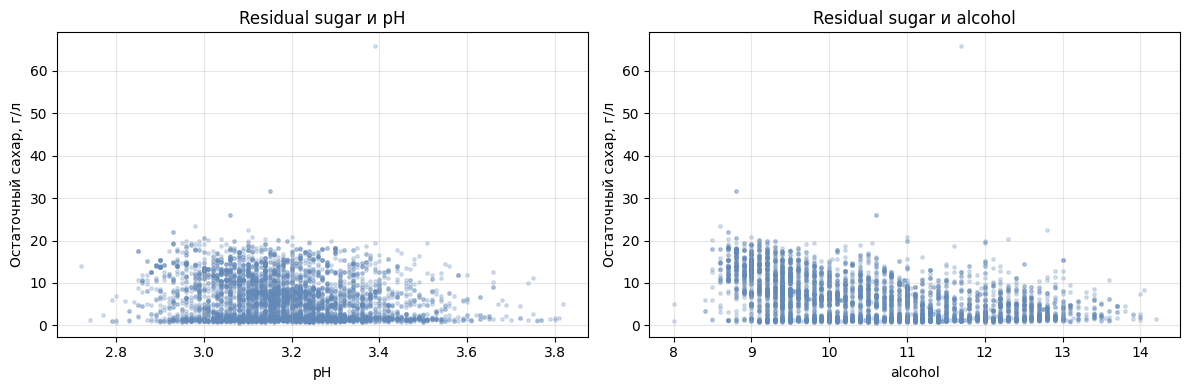

In [ ]:
for sugar_other_col in ["pH", "alcohol"]:
    r, p = stats.pearsonr(df["residual sugar"], df[sugar_other_col])
    rho, p_s = stats.spearmanr(df["residual sugar"], df[sugar_other_col])
    print(f"residual sugar / {sugar_other_col}: Пирсон r={r:.4f} (p={p:.2e}); "
          f"Спирмен rho={rho:.4f} (p={p_s:.2e})")

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, sugar_other_col in zip(axs, ["pH", "alcohol"]):
    ax.scatter(df[sugar_other_col], df["residual sugar"], s=6, alpha=.25)
    ax.set(xlabel=sugar_other_col, ylabel="Остаточный сахар, г/л",
           title=f"Residual sugar и {sugar_other_col}")
plt.tight_layout()
plt.show()

#### Анализ корреляций

Остаточный сахар имеет **слабую отрицательную корреляцию с pH** (Пирсон $r=-0.194$, Спирмен $\rho=-0.180$) и **умеренную отрицательную корреляцию с алкоголем** ($r=-0.451$, $\rho=-0.445$).

Малые значения p-value указывают на статистическую значимость связей. Следовательно, показатели не являются независимыми.

Наиболее выражена обратная связь сахара и алкоголя, что согласуется с процессом брожения, при котором сахар превращается в этанол. Однако корреляция не доказывает причинно-следственную связь.


Критерий χ² для пары alcohol и residual sugar приведён один раз в разделе «Независимость трёх величин» (перед Lab resume).

#### Состоятельность оценок

   n  RMSE среднего, г/л
  10             1.63642
  30             0.92322
 100             0.51789
 300             0.27272
1000             0.13966
3000             0.08352


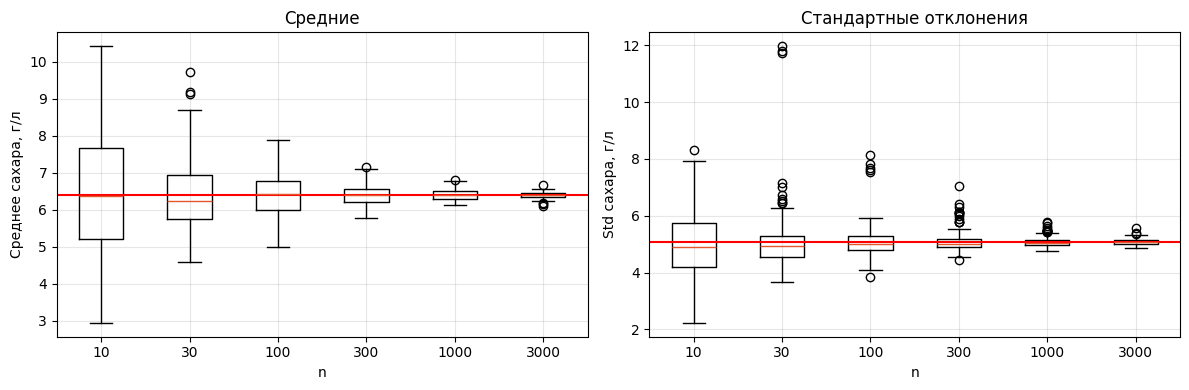

In [ ]:
sugar_rng = np.random.default_rng(SEED)
sugar_sizes = [10, 30, 100, 300, 1000, 3000]
sugar_means = []
sugar_stds = []
sugar_rmses = []
for sample_size in sugar_sizes:
    ms, ss = [], []
    for _ in range(200):
        sampled_sugar = sugar_rng.choice(sugar_values, size=sample_size, replace=True)
        ms.append(sampled_sugar.mean())
        ss.append(sampled_sugar.std(ddof=1))
    sugar_means.append(ms)
    sugar_stds.append(ss)
    sugar_rmses.append(np.sqrt(np.mean((np.array(ms) - sugar_values.mean()) ** 2)))

print(pd.DataFrame({"n": sugar_sizes, "RMSE среднего, г/л": sugar_rmses}).round(5).to_string(index=False))
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].boxplot(sugar_means, tick_labels=sugar_sizes)
axs[0].axhline(sugar_values.mean(), color="red")
axs[0].set(xlabel="n", ylabel="Среднее сахара, г/л", title="Средние")
axs[1].boxplot(sugar_stds, tick_labels=sugar_sizes)
axs[1].axhline(sugar_values.std(ddof=1), color="red")
axs[1].set(xlabel="n", ylabel="Std сахара, г/л", title="Стандартные отклонения")
plt.tight_layout()
plt.show()

По мере увеличения $n$ оценки среднего и стандартного отклонения концентрируются вокруг значений для всей таблицы (красные линии), а RMSE среднего уменьшается. Это иллюстрирует состоятельность оценок: при больших выборках случайная ошибка становится меньше. Из-за тяжёлого правого хвоста редкие большие значения сахара могут заметно менять стандартное отклонение в маленьких выборках. В эксперименте выборка берётся **с возвращением**, а «истинные» параметры условно равны статистикам 4898 записей, не всех белых вин в мире.

#### Выборки с возвращением и без

In [ ]:
sugar_rng = np.random.default_rng(SEED)
sugar_n = N_SAMPLE
sugar_without = sugar_rng.choice(sugar_values, sugar_n, replace=False)
sugar_with = sugar_rng.choice(sugar_values, sugar_n, replace=True)
print(pd.DataFrame({
    "Вся таблица": [sugar_values.mean(), sugar_values.std(ddof=1), np.median(sugar_values),
                    stats.skew(sugar_values, bias=False)],
    "Без возвращения": [sugar_without.mean(), sugar_without.std(ddof=1), np.median(sugar_without),
                         stats.skew(sugar_without, bias=False)],
    "С возвращением": [sugar_with.mean(), sugar_with.std(ddof=1), np.median(sugar_with),
                        stats.skew(sugar_with, bias=False)]
}, index=["Среднее", "Std", "Медиана", "Асимметрия"]).round(4).to_string())

sugar_rng = np.random.default_rng(SEED)
sugar_rep = 1000
sugar_m_no = np.array([sugar_rng.choice(sugar_values, sugar_n, replace=False).mean()
                       for _ in range(sugar_rep)])
sugar_m_yes = np.array([sugar_rng.choice(sugar_values, sugar_n, replace=True).mean()
                        for _ in range(sugar_rep)])
sugar_N = len(sugar_values)
sugar_sigma_N = sugar_values.std(ddof=0)
sugar_se_yes = sugar_sigma_N / np.sqrt(sugar_n)
sugar_se_no = sugar_se_yes * np.sqrt((sugar_N - sugar_n) / (sugar_N - 1))
print(f"Без возвращения: разброс средних {sugar_m_no.std(ddof=1):.5f}, теория {sugar_se_no:.5f}")
print(f"С возвращением: разброс средних {sugar_m_yes.std(ddof=1):.5f}, теория {sugar_se_yes:.5f}")

            Вся таблица  Без возвращения  С возвращением
Среднее          6.3914           6.4448          6.5832
Std              5.0721           5.0270          5.1802
Медиана          5.2000           5.4000          5.3500
Асимметрия       1.0771           0.7351          0.7534
Без возвращения: разброс средних 0.21220, теория 0.21494
С возвращением: разброс средних 0.22722, теория 0.22681


При выборке **с возвращением** одно наблюдение может выбираться несколько раз, а **без возвращения** — только один раз.

Теоретическая стандартная ошибка среднего:

**С возвращением:**

$$
SE = \frac{\sigma_N}{\sqrt{n}}
$$

**Без возвращения:**

$$
SE = \frac{\sigma_N}{\sqrt{n}}\sqrt{\frac{N-n}{N-1}}
$$

При $N=4898$ и $n=500$ стандартные ошибки составляют **0.2268 г/л** и **0.2149 г/л** соответственно.

Таким образом, **выборка без возвращения имеет меньший разброс среднего** благодаря поправке на конечную совокупность. Для проверки результата проводится **1000 повторных выборок**, после чего экспериментальные значения сравниваются с теоретическими.

**Результаты эксперимента.** На 1000 повторов разброс средних: без возвращения 0.2122 г/л (теория 0.2149), с возвращением 0.2272 г/л (теория 0.2268). Без возвращения разброс меньше, как и предсказывает поправка на конечную совокупность. В единичных выборках по 500 асимметрия (0.74 и 0.75) заметно ниже, чем во всей таблице (1.08): редкие вина с очень большим сахаром в выборку почти не попадают, а они и дают хвост.

#### Проверка гипотезы

In [ ]:
sugar_rng = np.random.default_rng(SEED)
sugar_sample = sugar_rng.choice(sugar_values, size=N_SAMPLE, replace=False)
sugar_mu0 = 6.4  # г/л; условное проверяемое значение, а не отраслевой норматив
sugar_test = stats.ttest_1samp(sugar_sample, sugar_mu0)
sugar_ci = stats.t.interval(.95, df=len(sugar_sample)-1,
                            loc=sugar_sample.mean(), scale=stats.sem(sugar_sample))
sugar_full_test = stats.ttest_1samp(sugar_values, sugar_mu0)
print(f"Выборка n=N_SAMPLE: mean={sugar_sample.mean():.6f} г/л, "
      f"t={sugar_test.statistic:.4f}, p={sugar_test.pvalue:.6f}")
print(f"95%-й ДИ для среднего: [{sugar_ci[0]:.4f}; {sugar_ci[1]:.4f}] г/л")
print(f"Вся таблица: t={sugar_full_test.statistic:.4f}, p={sugar_full_test.pvalue:.6f}")
print("Решение при α=0.05:",
      "отвергаем H0" if sugar_test.pvalue < .05 else "нет оснований отвергнуть H0")

Выборка n=N_SAMPLE: mean=6.444800 г/л, t=0.1993, p=0.842130
95%-й ДИ для среднего: [6.0031; 6.8865] г/л
Вся таблица: t=-0.1185, p=0.905708
Решение при α=0.05: нет оснований отвергнуть H0


Проверяем гипотезы о среднем содержании остаточного сахара:

$$
H_0: \mu = 6.4 \text{ г/л}
$$

$$
H_1: \mu \neq 6.4 \text{ г/л}
$$

Уровень значимости: $\alpha = 0.05$. Значение 6.4 г/л выбрано условно, как близкое к среднему по данным.

Для выборки из **500 наблюдений** рассчитываются t-статистика, p-value и 95%-й доверительный интервал. Аналогичный тест проводится для всей таблицы.

Если $p < 0.05$, **нулевая гипотеза отвергается**, иначе оснований для её отклонения недостаточно.

При большом объёме выборки применение t-теста обосновано центральной предельной теоремой. Однако асимметрия данных, выбросы и возможная зависимость наблюдений могут влиять на точность результатов.

**Результат.** На выборке из 500: среднее 6.4448 г/л, t = 0.199, p = 0.842, 95%-й ДИ [6.00; 6.89], поэтому $H_0$ не отвергаем. На всей таблице t = −0.119, p = 0.906, вывод тот же. Гипотеза взята рядом со средним, поэтому «не отвергнута» ожидаемо; отдельная проверка со сравнением групп по качеству приведена ниже.

In [ ]:
# Гипотеза: остаточный сахар у вин с высокой и низкой оценкой качества различается
high = df.loc[df["quality"] >= 7, "residual sugar"]
low = df.loc[df["quality"] <= 5, "residual sugar"]
u, p_u = stats.mannwhitneyu(high, low, alternative="two-sided")
rbc = 2 * u / (len(high) * len(low)) - 1   # ранговая бисериальная корреляция (размер эффекта)
print("Вин с quality >= 7:", len(high), ", с quality <= 5:", len(low))
print("Медиана residual sugar: высокое качество =", high.median(), ", низкое =", low.median())
print("U =", u, ", p =", p_u, ", размер эффекта (r_rb) =", round(rbc, 3))

Вин с quality >= 7: 1060 , с quality <= 5: 1640
Медиана residual sugar: высокое качество = 3.875 , низкое = 6.625
U = 734322.5 , p = 9.136645717794553e-12 , размер эффекта (r_rb) = -0.155


**Дополнительная гипотеза: различается ли остаточный сахар у вин разного качества?**

Сравниваем вина с `quality ≥ 7` ($n=1060$) и `quality ≤ 5` ($n=1640$).
$H_0$: распределения остаточного сахара в группах одинаковы; $H_1$: различаются; $\alpha=0.05$.
Выбран двусторонний критерий Манна — Уитни, позволяющий сравнить распределения без предположения нормальности.

Медиана сахара в группе высокого качества — **3.875 г/л**, низкого качества — **6.625 г/л**.
Получено $U=734322.5$, $p=9.14\cdot10^{-12}$, $r_{rb}=-0.155$.
Нулевая гипотеза отвергается: распределения статистически различаются, но **размер эффекта небольшой**.
В группе с более высокой оценкой наблюдается тенденция к меньшему содержанию сахара; причинную связь этот тест не устанавливает.


### Итоговый вывод по residual sugar

Остаточный сахар — неотрицательная непрерывная случайная величина: концентрация зависит от состава винограда и условий брожения. По 4898 наблюдениям среднее составляет **6.3914 г/л**, медиана — **5.2 г/л**, стандартное отклонение — **5.0721 г/л**. Положительная асимметрия **1.0771**, эксцесс **3.4698** и максимум **65.8 г/л** характеризуют выраженный правый хвост.

По тесту Шапиро — Уилка нормальность отвергается. Среди четырёх моделей минимальный AIC у гамма-распределения, тогда как наименьшее расстояние KS у логнормального. Ни одна из рассмотренных гладких моделей не воспроизводит распределение идеально. После стандартизации среднее становится равным нулю, а стандартное отклонение — единице, но асимметрия не исчезает.

Связь сахара с pH слабая отрицательная ($r\approx-0.19$), с алкоголем — умеренная отрицательная ($r\approx-0.45$). В экспериментах с увеличением размера выборки оценки среднего и стандартного отклонения становятся устойчивее; выборка без возвращения даёт меньшую стандартную ошибку среднего. Гипотеза о среднем содержании сахара **6.4 г/л** на выборке из 500 записей не отвергается ($p=0.842$). Дополнительно обнаружено статистически значимое, но небольшое различие распределений сахара между группами качества ($p=9.14\cdot10^{-12}$).

Для генератора во втором спринте можно сравнить гамма-модель с эмпирическим квантильным преобразованием: последнее лучше сохранит фактическую частотную структуру и хвост наблюдаемого распределения.


## Random Variable 03 (alcohol)

### Description

**Случайная величина:** объёмная доля этилового спирта в белом вине (alcohol). Данные — 4898 строк таблицы Wine Quality (белые вина).

| Характеристика | Значение |
|---|---|
| Единицы измерения | % об. |
| Физический тип | непрерывная |
| В таблице | 103 уникальных записанных значения |
| Диапазон | 8.0–14.2 % об. |
| Среднее | 10.5143 % об. |

**Обоснование случайности.** Алкоголь конкретного вина зависит от исходной сахаристости винограда, температуры и длительности брожения, активности дрожжей и технологических условий. Эти факторы заранее неизвестны для случайно выбранного образца. Процесс подчиняется физико-химическим закономерностям, но содержание алкоголя без информации об условиях и измерений нельзя однозначно вычислить по одной универсальной формуле. Погрешность измерения также вносит разброс.

Физическая величина непрерывна, но в датасете измерения округлены и записаны с конечной точностью. Поэтому 103 различных значения — следствие формы записи, а не доказательство физической дискретности. В таблице есть одинаковые строки; сохраняем их, как в анализе pH: без идентификаторов неизвестно, дубликаты ли это наблюдений или разные образцы с совпавшими результатами.

**Вывод:** содержание алкоголя можно рассматривать как случайную величину при случайном выборе вина из представленной совокупности.

In [ ]:
alcohol = df["alcohol"].dropna()
a = alcohol.to_numpy()
print("Число наблюдений:", len(a))
print("Уникальные записанные значения:", alcohol.nunique())
print("Наиболее частые значения (% об.):")
print(alcohol.value_counts().head(10).to_string())

Число наблюдений: 4898
Уникальные записанные значения: 103
Наиболее частые значения (% об.):
alcohol
9.4     229
9.5     228
9.2     199
9.0     185
10.0    162
10.5    160
11.0    158
10.4    153
9.1     144
9.8     136


### EDA & Distribution

#### Описательная статистика и выбросы

n             4898.0000
среднее         10.5143
медиана         10.4000
мода             9.4000
std              1.2306
min              8.0000
max             14.2000
Q1               9.5000
Q3              11.4000
асимметрия       0.4873
эксцесс         -0.6984
Границы по правилу 1.5 IQR: 6.65 ... 14.25
Число формальных выбросов: 0


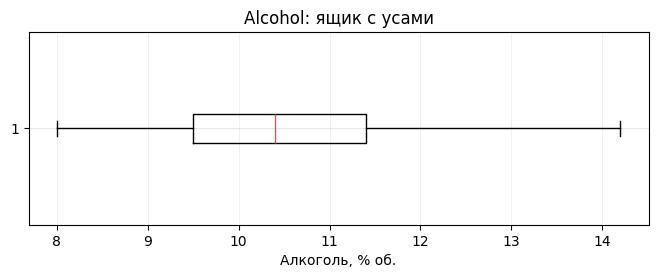

In [ ]:
alcohol_description = pd.Series({
    "n": alcohol.count(),
    "среднее": alcohol.mean(),
    "медиана": alcohol.median(),
    "мода": alcohol.mode().iloc[0],
    "std": alcohol.std(ddof=1),
    "min": alcohol.min(),
    "max": alcohol.max(),
    "Q1": alcohol.quantile(.25),
    "Q3": alcohol.quantile(.75),
    "асимметрия": alcohol.skew(),
    "эксцесс": alcohol.kurt()
})
print(alcohol_description.round(4).to_string())
q1, q3 = alcohol.quantile([.25,.75])
lower, upper = q1-1.5*(q3-q1), q3+1.5*(q3-q1)
print(f"Границы по правилу 1.5 IQR: {lower:.2f} ... {upper:.2f}")
print("Число формальных выбросов:", int(((alcohol<lower)|(alcohol>upper)).sum()))
plt.figure(figsize=(8,2.5))
plt.boxplot(a,vert=False)
plt.xlabel("Алкоголь, % об.")
plt.title("Alcohol: ящик с усами")
plt.grid(axis="x",alpha=.2)
plt.show()

**Интерпретация.** Среднее **10.5143 % об.**, медиана **10.4 % об.**, стандартное отклонение **1.2306 процентного пункта**. Асимметрия **0.4873** указывает на умеренный правый хвост; отрицательный эксцесс **−0.6984** — на более плоское распределение по сравнению с нормальным. Q1 = 9.5, Q3 = 11.4. По правилу 1.5 IQR выбросов нет, поэтому наблюдения не удаляем.

#### Форма распределения, Q–Q график и тест Шапиро–Уилка

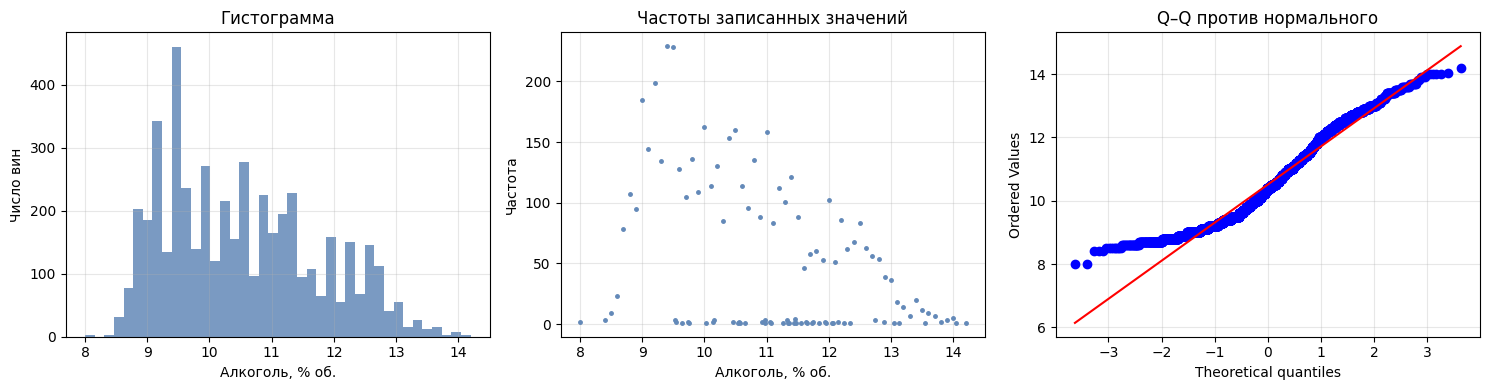

Шапиро–Уилк: W=0.955302; p=2.569e-36


In [ ]:
fig,axs=plt.subplots(1,3,figsize=(15,4))
axs[0].hist(a,bins=40,color="#6389B8",alpha=.85)
axs[0].set(xlabel="Алкоголь, % об.",ylabel="Число вин",title="Гистограмма")
freq=alcohol.value_counts().sort_index()
axs[1].plot(freq.index,freq.values,".",markersize=5)
axs[1].set(xlabel="Алкоголь, % об.",ylabel="Частота",title="Частоты записанных значений")
stats.probplot(a,dist="norm",plot=axs[2])
axs[2].set_title("Q–Q против нормального")
plt.tight_layout()
plt.show()
w,p_shapiro=stats.shapiro(a)
print(f"Шапиро–Уилк: W={w:.6f}; p={p_shapiro:.3e}")

Гистограмма имеет несколько пиков и «зубцы» вследствие повторяющихся округлённых измерений. Точки на Q–Q графике отклоняются от линии нормального распределения, особенно в хвостах. **Шапиро–Уилк:** $W=0.9553$, $p=2.57\cdot10^{-36}$; при $\alpha=0.05$ гипотезу точной нормальности отвергаем. Из-за большого $n$ тест чувствителен к небольшим нарушениям формы, поэтому дополнительно сравним несколько моделей.

#### Подбор распределения: нормальное, скошенное нормальное, гамма

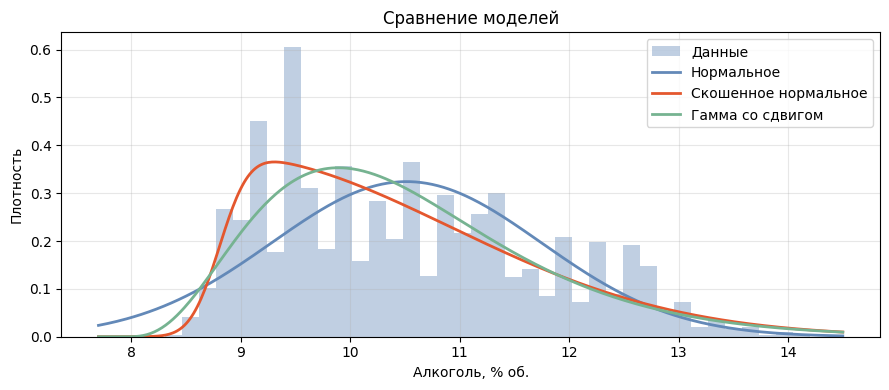

              Модель  k        AIC   KS D
Скошенное нормальное  3 15125.2840 0.0569
    Гамма со сдвигом  3 15358.8376 0.0729
          Нормальное  2 15935.7737 0.0916
Параметры skew-normal: shape, loc, scale = (np.float64(9.981325379517678), np.float64(8.806782475860167), np.float64(2.1046650921103787))


In [ ]:
models={
    "Нормальное":stats.norm,
    "Скошенное нормальное":stats.skewnorm,
    "Гамма со сдвигом":stats.gamma
}
results=[]; fitted={}
x=np.linspace(a.min()-.3,a.max()+.3,400)
plt.figure(figsize=(9,4))
plt.hist(a,bins=40,density=True,alpha=.4,color="#6389B8",label="Данные")
for name,model in models.items():
    pars=model.fit(a)
    fitted[name]=pars
    ll=model.logpdf(a,*pars).sum()
    aic=2*len(pars)-2*ll
    ks=stats.kstest(a,model.cdf,args=pars).statistic
    results.append([name,len(pars),aic,ks])
    plt.plot(x,model.pdf(x,*pars),label=name,linewidth=2)
plt.xlabel("Алкоголь, % об.")
plt.ylabel("Плотность")
plt.title("Сравнение моделей")
plt.legend()
plt.tight_layout()
plt.show()
print(pd.DataFrame(results,columns=["Модель","k","AIC","KS D"]).sort_values("AIC").round(4).to_string(index=False))
print("Параметры skew-normal: shape, loc, scale =",fitted["Скошенное нормальное"])

**Результаты:**

| Распределение | AIC | KS D |
|---|---:|---:|
| Нормальное | 15935.77 | 0.09160 |
| Гамма со сдвигом | 15358.84 | 0.07290 |
| Скошенное нормальное | **15125.28** | **0.05687** |

Из этих трёх моделей **скошенное нормальное лучше всего согласуется с данными** по AIC и расстоянию KS. Его параметры: shape ≈ 9.9813, loc ≈ 8.8068, scale ≈ 2.1047. Но идеального соответствия нет: гладкая модель не повторяет локальные пики. Значение p-value обычного теста Колмогорова–Смирнова здесь не используем, поскольку параметры подбирались по той же выборке, а данные имеют повторяющиеся округлённые значения. AIC учитывает штраф за число параметров; KS D используем лишь для относительного сравнения.

#### Математическая база распределения

Плотность **нормального распределения**:
$$f_N(x)=\frac{1}{\sigma\sqrt{2\pi}}\exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right),$$
где $\mu$ — среднее, $\sigma>0$ — стандартное отклонение. Нормальное распределение симметрично, его асимметрия и эксцесс равны нулю. Оно возникает как приближение результата суммы большого числа слабых независимых воздействий, но в этих данных симметрии недостаточно.

Плотность **скошенного нормального**:
$$f_{SN}(x)=\frac{2}{\omega}\varphi\left(\frac{x-\xi}{\omega}\right)
\Phi\left(\alpha\frac{x-\xi}{\omega}\right),$$
где $\varphi,\Phi$ — плотность и функция распределения стандартизованной нормальной величины, $\xi$ задаёт положение (loc), $\omega>0$ — масштаб (scale), $\alpha$ — асимметрию (shape). При $\alpha=0$ получаем нормальное распределение, при положительном $\alpha$ допускается правосторонняя асимметрия. Параметр loc не равен в общем случае среднему: если $\delta=\alpha/\sqrt{1+\alpha^2}$, то $E(X)=\xi+\omega\delta\sqrt{2/\pi}$.

Параметры оцениваем методом максимального правдоподобия через scipy.stats.skewnorm.fit. Для наблюдений с повторяющимися округлёнными значениями можно также использовать **эмпирическое распределение**:
$$\widehat P(X=x_i)=\frac{n_i}{N},\qquad
\widehat F(x)=\frac1N\sum_{j=1}^{N}\mathbf 1(X_j\le x).$$
Здесь $n_i$ — число повторений значения, $N=4898$. Такая модель сохраняет фактические частоты и подходит для последующего генератора по обратной функции распределения $X=\widehat F^{-1}(U)$, где $U\sim\mathrm{Uniform}(0,1)$.

#### Нормализация

Среднее после стандартизации: -3.7137390844137537e-16
Std после стандартизации: 0.9999999999999981
Асимметрия до и после: 0.4873419932161276 0.48734199321612887


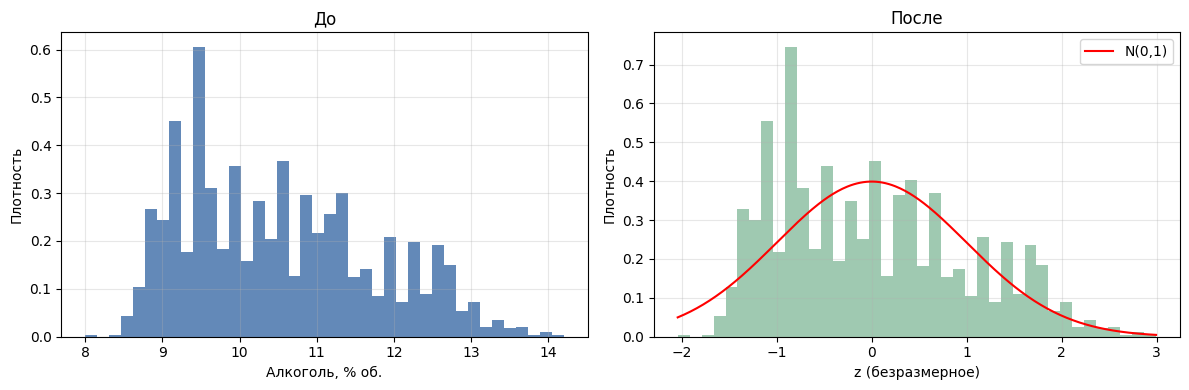

In [ ]:
z=(alcohol-alcohol.mean())/alcohol.std(ddof=1)
print("Среднее после стандартизации:",z.mean())
print("Std после стандартизации:",z.std(ddof=1))
print("Асимметрия до и после:",alcohol.skew(),z.skew())
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].hist(a,bins=40,density=True,color="#6389B8")
axs[0].set(xlabel="Алкоголь, % об.",ylabel="Плотность",title="До")
axs[1].hist(z,bins=40,density=True,color="#76B391",alpha=.7)
grid=np.linspace(z.min(),z.max(),300)
axs[1].plot(grid,stats.norm.pdf(grid),color="red",label="N(0,1)")
axs[1].set(xlabel="z (безразмерное)",ylabel="Плотность",title="После")
axs[1].legend()
plt.tight_layout()
plt.show()

После стандартизации $z_i=(x_i-\bar x)/s$ среднее практически равно нулю, стандартное отклонение — единице. Асимметрия остаётся **0.4873**. Стандартизация меняет центр и масштаб, **но не делает распределение нормальным**.

### Independence & Estimations

#### Зависимость от pH и остаточного сахара

alcohol / pH: Пирсон r=0.1214 (p=1.49e-17); Спирмен rho=0.1489 (p=1.14e-25)
alcohol / residual sugar: Пирсон r=-0.4506 (p=1.21e-243); Спирмен rho=-0.4453 (p=3.09e-237)


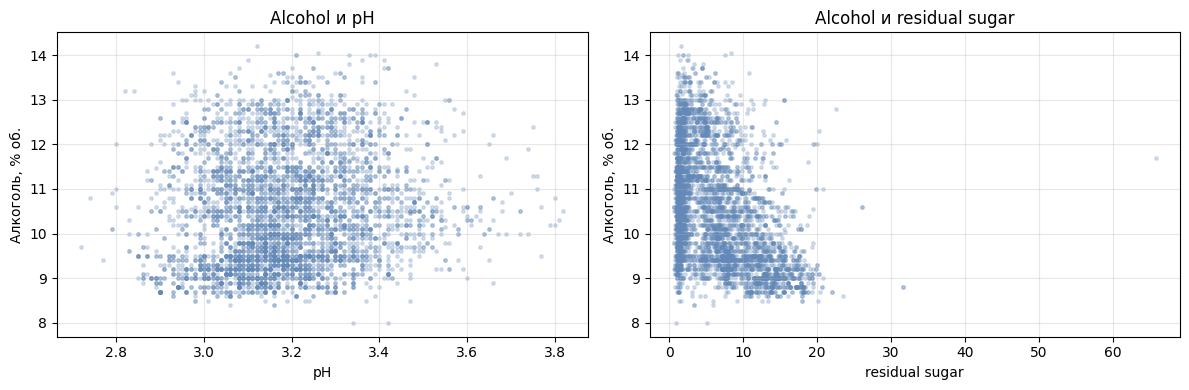

In [ ]:
for col in ["pH","residual sugar"]:
    r,p=stats.pearsonr(df["alcohol"],df[col])
    rho,p_s=stats.spearmanr(df["alcohol"],df[col])
    print(f"alcohol / {col}: Пирсон r={r:.4f} (p={p:.2e}); Спирмен rho={rho:.4f} (p={p_s:.2e})")
fig,axs=plt.subplots(1,2,figsize=(12,4))
for ax,col in zip(axs,["pH","residual sugar"]):
    ax.scatter(df[col],df["alcohol"],s=6,alpha=.25)
    ax.set(xlabel=col,ylabel="Алкоголь, % об.",title=f"Alcohol и {col}")
plt.tight_layout()
plt.show()

Алкоголь и pH связаны **слабо положительно**: $r=0.1214$, $\rho=0.1489$. Связь с остаточным сахаром **умеренная отрицательная**: $r=-0.4506$, $\rho=-0.4453$. p-value малы даже для слабой корреляции из-за большого объёма данных. Ненулевая корреляция показывает отсутствие строгой независимости, но сама по себе не доказывает причинность. Отрицательная связь алкоголя и остаточного сахара согласуется с превращением сахаров в этанол при брожении.

Критерий χ² для пары alcohol и residual sugar приведён один раз в разделе «Независимость трёх величин» (перед Lab resume).

#### Состоятельность оценок

   n  RMSE среднего
  10        0.39271
  30        0.23468
 100        0.12422
 300        0.06881
1000        0.03721
3000        0.02338


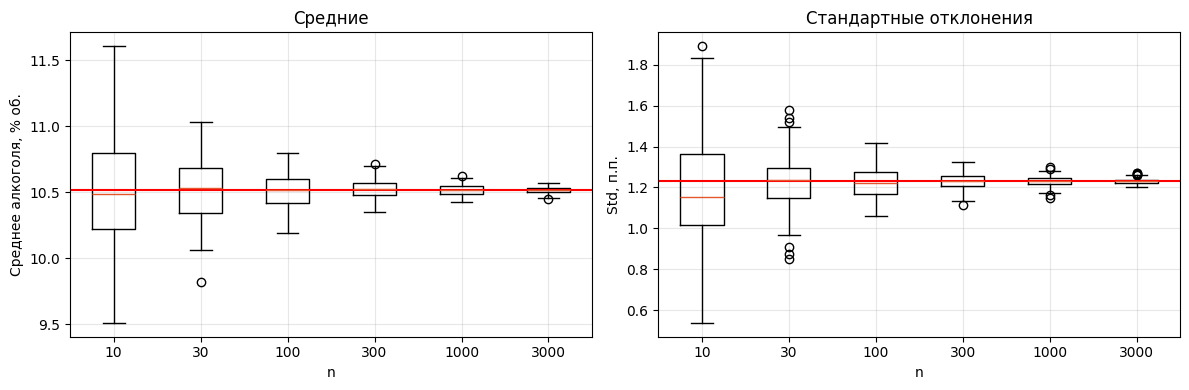

In [ ]:
rng=np.random.default_rng(SEED)
sizes=[10,30,100,300,1000,3000]
means=[]; stds=[]; rmses=[]
for n in sizes:
    ms=[]; ss=[]
    for _ in range(200):
        sample=rng.choice(a,size=n,replace=True)
        ms.append(sample.mean())
        ss.append(sample.std(ddof=1))
    means.append(ms); stds.append(ss)
    rmses.append(np.sqrt(np.mean((np.array(ms)-a.mean())**2)))
print(pd.DataFrame({"n":sizes,"RMSE среднего":rmses}).round(5).to_string(index=False))
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].boxplot(means,tick_labels=sizes)
axs[0].axhline(a.mean(),color="red")
axs[0].set(xlabel="n",ylabel="Среднее алкоголя, % об.",title="Средние")
axs[1].boxplot(stds,tick_labels=sizes)
axs[1].axhline(a.std(ddof=1),color="red")
axs[1].set(xlabel="n",ylabel="Std, п.п.",title="Стандартные отклонения")
plt.tight_layout()
plt.show()

С ростом $n$ разброс выборочных средних и стандартных отклонений сокращается: ящики становятся уже и располагаются около соответствующих характеристик полной таблицы. RMSE среднего также уменьшается. Это **эмпирическая иллюстрация состоятельности** оценок. Выборка берётся с возвращением, а «истинные» значения в этом эксперименте — статистики 4898 строк, не параметры всех белых вин в мире.

#### Выборки с возвращением и без

In [ ]:
rng=np.random.default_rng(SEED)
n=N_SAMPLE
without=rng.choice(a,n,replace=False)
with_repl=rng.choice(a,n,replace=True)
print(pd.DataFrame({
    "Вся таблица":[a.mean(),a.std(ddof=1),np.median(a)],
    "Без возвращения":[without.mean(),without.std(ddof=1),np.median(without)],
    "С возвращением":[with_repl.mean(),with_repl.std(ddof=1),np.median(with_repl)]
},index=["Среднее","Std","Медиана"]).round(4).to_string())

rng=np.random.default_rng(SEED)
rep=1000
m_no=np.array([rng.choice(a,n,replace=False).mean() for _ in range(rep)])
m_yes=np.array([rng.choice(a,n,replace=True).mean() for _ in range(rep)])
N=len(a)
sigma_pop=a.std(ddof=0)
se_yes=sigma_pop/np.sqrt(n)
se_no=se_yes*np.sqrt((N-n)/(N-1))
print(f"Без возвращения: разброс средних {m_no.std(ddof=1):.5f}, теория {se_no:.5f}")
print(f"С возвращением: разброс средних {m_yes.std(ddof=1):.5f}, теория {se_yes:.5f}")

         Вся таблица  Без возвращения  С возвращением
Среднее      10.5143          10.5180         10.4805
Std           1.2306           1.2343          1.2361
Медиана      10.4000          10.3000         10.3000
Без возвращения: разброс средних 0.05254, теория 0.05215
С возвращением: разброс средних 0.05365, теория 0.05503


При выборе с возвращением повторение одного наблюдения возможно, без возвращения — нет. Для среднего теоретические ошибки:
$$SE_{\mathrm{с\,возвр.}}=\frac{\sigma_N}{\sqrt n},\quad
SE_{\mathrm{без\,возвр.}}=\frac{\sigma_N}{\sqrt n}\sqrt{\frac{N-n}{N-1}}.$$
При $N=4898$, $n=500$ они составляют приблизительно **0.0550** и **0.0521** процентного пункта. Вторая меньше из-за поправки на конечную совокупность. Одного сравнения выборок недостаточно, поэтому методики дополнительно проверены на 1000 повторов.

#### Проверка гипотезы

In [ ]:
rng=np.random.default_rng(SEED)
sample=rng.choice(a,size=N_SAMPLE,replace=False)
mu0=10.5
test=stats.ttest_1samp(sample,mu0)
ci=stats.t.interval(.95,df=N_SAMPLE-1,loc=sample.mean(),scale=stats.sem(sample))
full=stats.ttest_1samp(a,mu0)
print(f"Выборка n=N_SAMPLE: mean={sample.mean():.6f}, t={test.statistic:.4f}, p={test.pvalue:.6f}")
print(f"95%-й ДИ для среднего: [{ci[0]:.4f}; {ci[1]:.4f}] % об.")
print(f"Вся таблица: t={full.statistic:.4f}, p={full.pvalue:.6f}")

Выборка n=N_SAMPLE: mean=10.517967, t=0.3255, p=0.744946
95%-й ДИ для среднего: [10.4095; 10.6264] % об.
Вся таблица: t=0.8114, p=0.417192


Проверяем $H_0:\mu=10.5\%$, $H_1:\mu\ne10.5\%$, $\alpha=0.05$. На случайной выборке из 500 строк (seed=42) **среднее = 10.5180 % об.**, $t=0.3255$, $p=0.7449>0.05$, следовательно, **нет оснований отвергнуть $H_0$**. 95%-й доверительный интервал **[10.4095; 10.6264] % об.** содержит 10.5%. На всей таблице $t=0.8114$, $p=0.4172$ — тот же вывод.

Неотвержение $H_0$ не доказывает точного равенства 10.5%. При $n=500$ t-тест для среднего достаточно устойчив к умеренной ненормальности благодаря центральной предельной теореме. Но результаты строго относятся к исследуемой таблице: распространение на все вина требует репрезентативного отбора и независимых наблюдений.

In [ ]:
# Гипотеза: спирт у вин с высокой и низкой оценкой качества различается
high = df.loc[df["quality"] >= 7, "alcohol"]
low = df.loc[df["quality"] <= 5, "alcohol"]
u, p_u = stats.mannwhitneyu(high, low, alternative="two-sided")
rbc = 2 * u / (len(high) * len(low)) - 1   # ранговая бисериальная корреляция (размер эффекта)
print("Вин с quality >= 7:", len(high), ", с quality <= 5:", len(low))
print("Медиана alcohol: высокое качество =", high.median(), ", низкое =", low.median())
print("U =", u, ", p =", p_u, ", размер эффекта (r_rb) =", round(rbc, 3))

Вин с quality >= 7: 1060 , с quality <= 5: 1640
Медиана alcohol: высокое качество = 11.5 , низкое = 9.6
U = 1446839.0 , p = 1.2818692810861878e-187 , размер эффекта (r_rb) = 0.665


**Дополнительная гипотеза: различается ли содержание алкоголя у вин разного качества?**

Сравниваем вина с `quality ≥ 7` ($n=1060$) и `quality ≤ 5` ($n=1640$).
$H_0$: распределения алкоголя в группах одинаковы; $H_1$: различаются; $\alpha=0.05$.
Использован двусторонний критерий Манна — Уитни без предположения нормальности.

Медиана содержания алкоголя в группе высокого качества — **11.5 % об.**, низкого качества — **9.6 % об.**
Получено $U=1446839$, $p=1.28\cdot10^{-187}$, $r_{rb}=0.665$.
Нулевая гипотеза отвергается: распределения значительно различаются, **размер эффекта большой**.
В этой выборке более высокие оценки связаны с большим содержанием алкоголя, однако статистическая связь не доказывает причинности.


### Итоговый вывод по alcohol

Объёмная доля алкоголя зависит от множества неконтролируемых условий и является случайной величиной для случайно выбранного вина. В исследуемых 4898 записях среднее **10.5143 % об.**, распределение умеренно асимметрично вправо и имеет пики из-за неоднородности и точности записи. Из трёх рассмотренных моделей лучше подходит **скошенное нормальное распределение**, но оно не идеально передаёт эмпирические частоты. Нормализация приводит среднее к нулю, а стандартное отклонение к единице, не убирая асимметрию. При увеличении размера выборки оценки становятся устойчивее; без возвращения разброс средних несколько меньше. Алкоголь умеренно отрицательно связан с остаточным сахаром и слабо положительно — с pH, то есть строгой независимости не обнаружено. Проверка гипотезы **$\mu=10.5\%$** не выявила значимого отличия. Для генератора во втором спринте целесообразно рассмотреть **эмпирическое квантильное преобразование**, сохраняющее частоты округлённых измерений.

**Литература:**
1. Cortez P. et al. Wine Quality [dataset]. UCI Machine Learning Repository (2009). https://doi.org/10.24432/C56S3T
2. SciPy Documentation, scipy.stats.skewnorm: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.skewnorm.html
3. SciPy Documentation, Statistical functions: https://docs.scipy.org/doc/scipy/reference/stats.html

## Независимость трёх величин

Величины измерены на одних и тех же винах, поэтому нужно показать, зависимы ли они. Корреляции для каждой пары показаны ниже, критерий χ² для самой связанной пары (alcohol и residual sugar) проведён один раз.

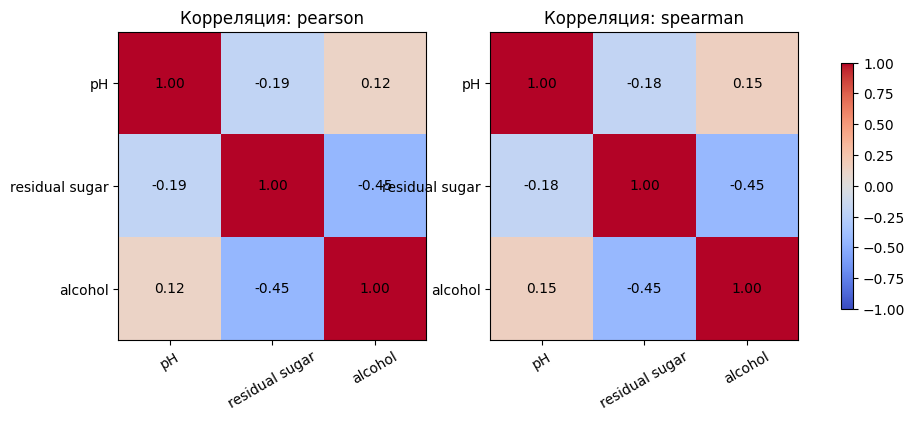

In [ ]:
cols = ["pH", "residual sugar", "alcohol"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = df[cols].corr(method=method)
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(3)); ax.set_xticklabels(cols, rotation=30)
    ax.set_yticks(range(3)); ax.set_yticklabels(cols)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
    ax.set_title("Корреляция: " + method)
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

In [ ]:
# Разбиваем непрерывные величины на 4 группы по квантилям
alc_q = pd.qcut(df["alcohol"], 4, duplicates="drop")
sug_q = pd.qcut(df["residual sugar"], 4, duplicates="drop")
table = pd.crosstab(alc_q, sug_q)
print(table)

chi2, p_chi, dof, expected = stats.chi2_contingency(table)
print("chi2 =", chi2, ", p =", p_chi, ", степеней свободы =", dof)
print("Минимальная ожидаемая частота:", expected.min())

n_obs = table.values.sum()
v = np.sqrt(chi2 / (n_obs * (min(table.shape) - 1)))
print("V Крамера =", v)

residual sugar  (0.599, 1.7]  (1.7, 5.2]  (5.2, 9.9]  (9.9, 65.8]
alcohol                                                          
(7.999, 9.5]             168         150         348          770
(9.5, 10.4]              317         208         359          253
(10.4, 11.4]             467         317         289          117
(11.4, 14.2]             305         537         222           71
chi2 = 1355.5173030641326 , p = 3.1515287876789917e-286 , степеней свободы = 9
Минимальная ожидаемая частота: 280.621682319314
V Крамера = 0.3037263807731856


**Независимость: критерий хи-квадрат**

Я разбила спирт и сахар на 4 группы по квантилям и построила таблицу
сопряжённости. chi2 = 1355, p = 3·10⁻²⁸⁶, число степеней свободы 9,
V Крамера = 0.30.
Это значит, что спирт и сахар зависимы, а связь умеренная.
По таблице видно, что среди вин с малым спиртом (до 9.5) много вин с
большим сахаром (770), а среди вин с большим спиртом (от 11.4) таких
всего 71.
Это совпадает с корреляцией Пирсона (r = −0.45): направление связи то
же. Сами числа 0.30 и 0.45 напрямую сравнивать нельзя, это разные меры,
и V Крамера зависит от того, как разбить данные на группы.
Хи-квадрат не требует линейной связи, поэтому вместе с корреляцией он
даёт более надёжный вывод.

## Литература
1. Cortez P., Cerdeira A., Almeida F., Matos T., Reis J. Modeling wine preferences by data mining from physicochemical properties // Decision Support Systems. 2009. Vol. 47, № 4. P. 547–553.
2. Cortez P. et al. Wine Quality [dataset]. UCI Machine Learning Repository, 2009. https://doi.org/10.24432/C56S3T
3. Гмурман В. Е. Теория вероятностей и математическая статистика.
4. Azzalini A. A class of distributions which includes the normal ones // Scandinavian Journal of Statistics. 1985. Vol. 12, № 2. P. 171–178.
5. Limpert E., Stahel W. A., Abbt M. Log-normal distributions across the sciences: keys and clues // BioScience. 2001. Vol. 51, № 5. P. 341–352.
6. Devroye L. Non-Uniform Random Variate Generation. New York: Springer, 1986.
7. SciPy documentation, scipy.stats: https://docs.scipy.org/doc/scipy/reference/stats.html
8. IUPAC Gold Book. pH. https://doi.org/10.1351/goldbook.P04524


## Lab resume


### Итоговый вывод по лабораторной работе

**Данные и величины.** Я проанализировала три величины из датасета Wine Quality
(4898 белых вин): pH, остаточный сахар (residual sugar) и спирт (alcohol).
Все три можно рассматривать как случайные величины: при случайном выборе образца его состав
и условия получения заранее неизвестны. Дополнительную вариативность результатов вносит погрешность измерения.

**Формы распределений.** Ни одна величина не оказалась нормальной. pH похож
на колокол с небольшим правым хвостом (асимметрия 0.46): по Шапиро-Уилку p ≈ 10⁻²⁰,
но W = 0.988, то есть отклонение от нормального небольшое. Сахар имеет сильный
правый хвост (асимметрия 1.08, эксцесс 3.47): много вин с малым сахаром и редкие
вина до 65.8 г/л. Спирт ближе всего к плоскому распределению (эксцесс −0.70),
а «зубцы» на гистограмме появились из-за того, что в данных только 103 разных
значения.

**Выбор распределений.** Для pH лучше лог-нормальное со сдвигом (AIC −4765
против −4616, KS 0.025 против 0.049). Для сахара по AIC лучшей оказалась гамма,
а по KS лог-нормальное, и все значения KS больше 0.11, поэтому простая гладкая
модель описывает его плохо. Для спирта лучше всех скошенное нормальное
(AIC 15125, KS 0.057), но оно тоже не повторяет локальные пики. Идеально не
подошло ни одно распределение, потому что реальные данные округлены и
получены смешением разных партий вин.

**Независимость.** Самая связанная пара: спирт и сахар (r = −0.45, V Крамера = 0.30).
Это согласуется с химией брожения: чем полнее дрожжи превращают сахар в спирт,
тем меньше остаётся сахара. pH связан с обеими величинами слабо (r = 0.12 и −0.19).
Все p-value очень малы, но это следствие большого объёма данных, поэтому я
опиралась на размер коэффициентов. Значит, pH можно моделировать почти отдельно,
а спирт и сахар по отдельности лучше не генерировать как независимые.

**Оценки и выборки.** Оценки среднего и стандартного отклонения состоятельны:
с ростом размера выборки они концентрируются вокруг значений по всей таблице
(RMSE среднего падает). Выборки без возвращения дали чуть меньший разброс
средних, чем с возвращением (pH: 0.0062 и 0.0068, сахар: 0.212 и 0.227 г/л),
что совпало с поправкой на конечную совокупность.

**Гипотезы.** Предположение о среднем pH = 3.2 на выборке из 500 вин не отвергается (p = 0.188),
а на всей таблице отвергается (p ≈ 6·10⁻⁸), но разница в 0.012 практически
ничтожна. Для сахара (6.4 г/л, p = 0.842) и спирта (10.5 %, p = 0.745)
гипотезы не отвергнуты. Дополнительно критерий Манна — Уитни выявил различия распределений pH, сахара и алкоголя между группами качества; наиболее крупный размер эффекта получен для алкоголя ($r_{rb}=0.665$).

**Что это говорит о винах.** Белые вина в датасете довольно
однородны по кислотности, диапазон pH узкий, а различия по сахару и спирту
связаны с тем, насколько полно прошло брожение.

**Ограничения и планы.** В таблице 937 повторяющихся строк, значения округлены,
а «истинные» значения в экспериментах это статистики 4898 строк, а не всех
белых вин. Во втором спринте я сделаю генераторы: для pH лог-нормальный через
нормальные числа, для сахара и спирта метод квантильного преобразования по
эмпирической функции распределения.


### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| Доказательство случайности величины | Random Variable 01–03 → Description | 1 | для каждой из трёх величин: неизвестные заранее факторы и погрешности измерения; единицы измерения в таблице |
| Независимость | «Независимость трёх величин» и Independence & Estimations | 1 | корреляции Пирсона и Спирмена для трёх пар, хи-квадрат и V Крамера для спирта и сахара |
| Состоятельность оценок | Random Variable 01–03 → Состоятельность оценок | 1 | ящики для n от 10 до 3000, RMSE среднего, смещение std при малых n |
| EDA, нормализация | Random Variable 01–03 → EDA & Distribution, Нормализация | 1 | статистики, выбросы, Q-Q график, Шапиро-Уилк, стандартизация |
| Выборка из генеральной совокупности (с возвращением и без) | Random Variable 01–03 → Выборки с возвращением и без | 1 | 1000 повторов, сравнение разброса средних с теорией |
| Математика распределения | Random Variable 01–03 → Математическая база | 1 | плотности, параметры, происхождение и особенности распределений |
| Проверка гипотез | Random Variable 01–03 → Проверка гипотезы | 1 | t-тест на выборке и всей таблице, критерий Манна-Уитни по качеству |
| За каждое распределение | EDA & Distribution | 1 | сравнено: нормальное, лог-нормальное, гамма, Вейбулла, экспоненциальное, скошенное нормальное (6 распределений) |
| Табличное представление метрик | Подбор распределения (RV02, RV03) | 1 | таблицы AIC и KS |
| Приведение к стандартному нормальному | Нормализация | — | выполнена стандартизация (среднее 0, std 1), но распределения не стали стандартно-нормальными; доп. критерий не заявляется |
| Список литературы | «Литература» | 1 | книги, статьи, документация, 8 источников |
| Версирование | история коммитов в GitHub | — | подтверждается историей GitHub, а не содержимым ноутбука |